# Ethylene case study

This notebook reproduces the illustrative case study used to demonstrate cost
minimization in time-explicit life cycle optimization. It constructs an ethylene
production system with three competing routes, solves the environmental and
economic optimization problems, and evaluates cost--climate trade-offs under
alternative market-price and technology-maturation assumptions.

The case study demonstrates the method; it is not intended as a forecast of the
future ethylene sector.

## 1. Scope and temporal background

The model covers 2025--2050 and supplies a constant annual demand of `1 Mt` of
ethylene. It uses time-specific background inventories generated with premise
from ecoinvent 3.12 (cut-off) and the REMIND-EU SSP2-NDC pathway for 2020, 2030,
2040, and 2050. Intermediate years are linked to these support years through the
time-explicit optimex workflow.

The climate-change indicator is IPCC 2021 GWP100, including hydrogen and
biogenic CO2. Costs are reported in real EUR 2025 and discounted to 2025 using
a real discount rate of 3%.

In [1]:
from datetime import datetime
from pathlib import Path
import logging
import warnings

import bw2data as bd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from bw_temporalis import TemporalDistribution
from IPython.display import display

from optimex.utils import (
    infer_construction_td_from_limits,
    infer_operation_td_from_limits,
)

PROJECT = "optimex_remind"
BIOSPHERE_DB = "ecoinvent-3.12-biosphere"
FOREGROUND_DB = "ethylene_case_study_foreground"
PREMISE_DBS = {
    2020: "ei312_REMIND-EU_SSP2_NDC_2020",
    2030: "ei312_REMIND-EU_SSP2_NDC_2030",
    2040: "ei312_REMIND-EU_SSP2_NDC_2040",
    2050: "ei312_REMIND-EU_SSP2_NDC_2050",
}
CASE_STUDY_BG_DBS = {
    year: f"ethylene_case_study_background_{year}"
    for year in PREMISE_DBS
}

bd.projects.set_current(PROJECT)
required_databases = {BIOSPHERE_DB, *PREMISE_DBS.values()}
missing_databases = required_databases - set(bd.databases)
if missing_databases:
    raise ValueError(f"Missing databases: {sorted(missing_databases)}")

logging.getLogger().setLevel(logging.WARNING)
warnings.filterwarnings("default")


## 2. Model assumptions

The following table records the numerical assumptions used to construct the
foreground system. `SOURCE-BASED` identifies values taken or derived from a
specific source, `INVENTORY` values are retained from the underlying LCI,
`MODELLING ASSUMPTION` denotes a deliberate case-study choice, and
`ILLUSTRATIVE PROXY` marks a transferred value used for the demonstration.

Plant lifetimes and capacity-related cost inputs are documented separately in
the versioned input files and in the references at the end of this notebook.

In [2]:
assumptions = pd.DataFrame(
    [
        ("lifetime.steam_cracking", 25, "year", "SOURCE-BASED", "Tiggeloven (2026), Table C.1, conventional cracker"),
        ("lifetime.dac", 20, "year", "SOURCE-BASED", "Deutz and Bardow (2021), https://doi.org/10.1038/s41560-020-00771-9"),
        ("lifetime.pem", 25, "year", "ILLUSTRATIVE PROXY", "Tiggeloven (2026), Table C.1, AEC plant; separate 9-year stack replacement not modeled"),
        ("lifetime.co2_hydrogenation", 25, "year", "SOURCE-BASED", "Tiggeloven (2026), Table C.1, direct methanol synthesis from CO2"),
        ("lifetime.mto", 25, "year", "SOURCE-BASED", "Tiggeloven (2026), Table C.1, methanol-to-olefins"),
        ("lifetime.eco2r", 25, "year", "ILLUSTRATIVE PROXY", "Tiggeloven (2026), Table C.1, CO2 electrolysis and air-separation-unit proxies"),
        ("capacity.steam_cracking", 1e9, "kg ethylene/a", "SOURCE-BASED", "Tiggeloven (2026), Chapter 2 reference cracker"),
        ("capacity.pem", 156414.347247488, "kg H2/a", "ILLUSTRATIVE PROXY", "1 MWe at 8760 h/a divided by 56.00509259 kWh/kg H2"),
        ("capacity.co2_hydrogenation", 6.134969325153374e9, "kg methanol/a", "SOURCE-BASED", "Sized to the methanol demand of the 1 Mt ethylene/a MTO reference using Tiggeloven Table C.2"),
        ("capacity.mto", 1e9, "kg ethylene/a", "SOURCE-BASED", "Common case-study reference output using Tiggeloven Table C.2"),
        ("capacity.eco2r", 1e9, "kg ethylene/a", "ILLUSTRATIVE PROXY", "Common case-study reference output using Tiggeloven CO2-electrolysis data"),
        ("allocation.steam_cracking", 0.5222337125129265, "fraction", "ILLUSTRATIVE PROXY", "PlasticsEurope main-product mass rule with Zimmermann and Walzl yields from Tiggeloven Table A.6"),
        ("allocation.pem", 1.0, "fraction", "MODELLING ASSUMPTION", "No product allocation in the foreground LCI"),
        ("allocation.co2_hydrogenation", 1.0, "fraction", "MODELLING ASSUMPTION", "No product allocation in the foreground LCI"),
        ("allocation.mto", 0.4, "fraction", "MODELLING ASSUMPTION", "disco2very mass allocation inherited by costs"),
        ("allocation.eco2r", 1.0, "fraction", "MODELLING ASSUMPTION", "No product allocation in the foreground LCI"),
        (
            "installation.steam_factory",
            1.1516356618335166e-10,
            "unit/kg ethylene",
            "INVENTORY",
            "ecoinvent net coefficient preserved through the route-specific wrapper",
        ),
        (
            "installation.dac_system",
            1.25e-8,
            "unit/kg CO2",
            "INVENTORY",
            "disco2very 4 kt CO2/a DAC inventory coefficient copied unchanged",
        ),
        (
            "installation.pem_stack",
            1.34989e-6,
            "unit/kg H2",
            "INVENTORY",
            "methanol_and_iron inventory coefficient copied unchanged",
        ),
        (
            "installation.pem_bop",
            3.37373e-7,
            "unit/kg H2",
            "INVENTORY",
            "methanol_and_iron inventory coefficient copied unchanged",
        ),
        (
            "installation.co2_hydrogenation_factory",
            3.5842e-12,
            "unit/kg methanol",
            "INVENTORY",
            "disco2very net coefficient preserved through the route-specific wrapper",
        ),
        (
            "installation.mto_factory",
            3.584e-12,
            "unit/kg ethylene",
            "INVENTORY",
            "disco2very net coefficient preserved through the route-specific wrapper",
        ),
        (
            "installation.eco2r_factory",
            4e-10,
            "unit installation/kg ethylene",
            "INVENTORY",
            "Corrected with the disco2very inventory creator: chemical factory construction, organics",
        ),
        (
            "installation.eco2r_copper",
            7.4e-11,
            "kg/kg ethylene",
            "INVENTORY",
            "Internal input of the aggregated eCO2R installation wrapper",
        ),
        (
            "installation.eco2r_steel",
            3.017679e-6,
            "kg/kg ethylene",
            "INVENTORY",
            "Internal input of the aggregated eCO2R installation wrapper",
        ),
        ("brownfield.vintage_1", 2005, "year", "ILLUSTRATIVE PROXY", "Illustrative brownfield assumption"),
        ("brownfield.vintage_2", 2015, "year", "ILLUSTRATIVE PROXY", "Illustrative brownfield assumption"),
        ("brownfield.capacity_per_vintage", 0.5e9, "kg ethylene/a", "ILLUSTRATIVE PROXY", "Illustrative brownfield assumption: two equal vintages"),
        ("economics.discount_rate", 0.03, "real fraction/a", "ILLUSTRATIVE PROXY", "Illustrative real discount rate"),
    ],
    columns=["parameter", "value", "unit", "status", "basis"],
).set_index("parameter")

PROCESS_NAMES = {
    "steam_cracking": "Steam cracking",
    "dac": "Direct air capture",
    "pem": "PEM electrolysis",
    "co2_hydrogenation": "CO2 hydrogenation to methanol",
    "mto": "Methanol-to-olefins",
    "eco2r": "eCO2R ethylene production",
}
LIFETIMES_YEARS = {
    process: int(assumptions.loc[f"lifetime.{process}", "value"])
    for process in PROCESS_NAMES
}
ENVIRONMENTAL_INSTALLATION_AMOUNTS = {
    key.removeprefix("installation."): float(row["value"])
    for key, row in assumptions.loc[
        assumptions.index.str.startswith("installation.")
    ].iterrows()
}
REFERENCE_CAPACITIES_KG_PER_YEAR = {
    process: float(assumptions.loc[f"capacity.{process}", "value"])
    for process in ["steam_cracking", "pem", "co2_hydrogenation", "mto", "eco2r"]
}
CAPEX_ALLOCATION_FACTORS = {
    process: float(assumptions.loc[f"allocation.{process}", "value"])
    for process in ["steam_cracking", "pem", "co2_hydrogenation", "mto", "eco2r"]
}
WRAPPER_INSTALLATION_AMOUNTS = {
    process: 1.0 / (
        REFERENCE_CAPACITIES_KG_PER_YEAR[process] * LIFETIMES_YEARS[process]
    )
    for process in REFERENCE_CAPACITIES_KG_PER_YEAR
}
assert np.isclose(WRAPPER_INSTALLATION_AMOUNTS["steam_cracking"], 4e-11, rtol=1e-12, atol=0.0)
assert np.isclose(WRAPPER_INSTALLATION_AMOUNTS["pem"], 2.55731016392694e-7, rtol=1e-12, atol=0.0)
assert np.isclose(WRAPPER_INSTALLATION_AMOUNTS["co2_hydrogenation"], 6.52e-12, rtol=1e-12, atol=0.0)
assert np.isclose(WRAPPER_INSTALLATION_AMOUNTS["mto"], 4e-11, rtol=1e-12, atol=0.0)
assert np.isclose(WRAPPER_INSTALLATION_AMOUNTS["eco2r"], 4e-11, rtol=1e-12, atol=0.0)

assumptions

,value,unit,status,basis
parameter,,,,
lifetime.steam_cracking,2.500000e+01,year,SOURCE-BASED,"Tiggeloven (2026), Table C.1, conventional cra..."
lifetime.dac,2.000000e+01,year,SOURCE-BASED,"Deutz and Bardow (2021), https://doi.org/10.10..."
lifetime.pem,2.500000e+01,year,ILLUSTRATIVE PROXY,"Tiggeloven (2026), Table C.1, AEC plant; separ..."
lifetime.co2_hydrogenation,2.500000e+01,year,SOURCE-BASED,"Tiggeloven (2026), Table C.1, direct methanol ..."
lifetime.mto,2.500000e+01,year,SOURCE-BASED,"Tiggeloven (2026), Table C.1, methanol-to-olefins"
lifetime.eco2r,2.500000e+01,year,ILLUSTRATIVE PROXY,"Tiggeloven (2026), Table C.1, CO2 electrolysis..."
capacity.steam_cracking,1.000000e+09,kg ethylene/a,SOURCE-BASED,"Tiggeloven (2026), Chapter 2 reference cracker"
capacity.pem,1.564143e+05,kg H2/a,ILLUSTRATIVE PROXY,1 MWe at 8760 h/a divided by 56.00509259 kWh/k...
capacity.co2_hydrogenation,6.134969e+09,kg methanol/a,SOURCE-BASED,Sized to the methanol demand of the 1 Mt ethyl...


## 3. Time-specific background inventories

Four background databases provide the time-specific supply chains used by
optimex. They are based on ecoinvent 3.12 and were generated with premise for
the REMIND-EU SSP2-NDC pathway. Transparent interface activities connect the
foreground processes to equivalent products in each background year. This
preserves a stable foreground interface while the supplying background system
changes over time.

In [3]:
PEI_NAME = "polyethyleneimine production"
PEI_PRODUCT = "polyethyleneimine"
ADSORBENT_NAME = "adsorbent, amine on alumina"
ADSORBENT_PRODUCT = "adsorbent, amine on alumina"
DAC_4KT_NAME = "direct air capture system construction, solid sorbent, 4 ktCO2/a"
DAC_4KT_PRODUCT = "direct air capture system, solid sorbent, 4 ktCO2/a"
FEEDSTOCK_MIX_NAME = "steam cracking feedstock mix"
STEAM_INSTALLATION_NAME = "steam cracker installation"
CO2_HYDROGENATION_INSTALLATION_NAME = "CO2 hydrogenation installation"
MTO_INSTALLATION_NAME = "methanol-to-olefins installation"
ECO2R_INSTALLATION_NAME = "eCO2R system installation"
PEM_INSTALLATION_NAME = "PEM electrolyzer system installation, 1 MWe"

STEAM_FEEDSTOCK_TOTAL = 1.21675954200327
STEAM_FEEDSTOCK_INPUTS = [
    ("market for butane", "butane", "RoW", "kilogram", 0.19711504876613617),
    ("market for ethane", "ethane", "RoW", "kilogram", 0.05475417897105217),
    ("market for naphtha", "naphtha", "RER", "kilogram", 0.7787261009216309),
    ("market for natural gas liquids", "natural gas liquids", "RoW", "kilogram", 0.02676870860159397),
    ("market for propane", "propane", "RoW", "kilogram", 0.09247373044490814),
    ("market for refinery gas", "refinery gas", "GLO", "kilogram", 0.018251389265060425),
    ("market for diesel", "diesel", "DEU", "kilogram", 0.04867038503289223),
]
assert np.isclose(
    sum(item[4] for item in STEAM_FEEDSTOCK_INPUTS),
    STEAM_FEEDSTOCK_TOTAL,
)

INTERFACE_SPECS = [
    ("cooling_minus_25", "cooling energy production, at -25 °C, propylene compression refrigeration system 1 MW", "cooling energy, at -25 °C", "GLO", "megajoule"),
    ("pem_bop", "electrolyzer production, 1MWe, PEM, Balance of Plant", "electrolyzer, 1MWe, PEM, Balance of Plant", "RER", "unit"),
    ("pem_stack", "electrolyzer production, 1MWe, PEM, Stack", "electrolyzer, 1MWe, PEM, Stack", "RER", "unit"),
    ("heat_pump", "heat production, at heat pump 30kW, allocation exergy", "heat, central or small-scale, other than natural gas", "Europe without Switzerland", "megajoule"),
    ("compressed_air", "market for compressed air, 700 kPa gauge", "compressed air, 700 kPa gauge", "RER", "cubic meter"),
    ("cooling", "market for cooling energy", "cooling energy", "GLO", "megajoule"),
    ("cooling_minus_100", "market for cooling energy, at -100 °C", "cooling energy, at -100 °C", "GLO", "megajoule"),
    ("cooling_minus_15", "market for cooling energy, at -15 °C", "cooling energy, at -15 °C", "GLO", "megajoule"),
    ("cooling_minus_45", "market for cooling energy, at -45 °C", "cooling energy, at -45 °C", "GLO", "megajoule"),
    ("cooling_minus_55", "market for cooling energy, at -55 °C", "cooling energy, at -55 °C", "GLO", "megajoule"),
    ("electricity_mv", "market for electricity, medium voltage", "electricity, medium voltage", "DE", "kilowatt hour"),
    ("hazardous_waste_incineration", "market for hazardous waste, for incineration", "hazardous waste, for incineration", "CH", "kilogram"),
    ("hazardous_waste_underground", "market for hazardous waste, for underground deposit", "hazardous waste, for underground deposit", "RER", "kilogram"),
    ("industrial_heat", "market for heat, district or industrial, natural gas", "heat, district or industrial, natural gas", "Europe without Switzerland", "megajoule"),
    ("inert_waste", "market for inert waste, for final disposal", "inert waste, for final disposal", "CH", "kilogram"),
    ("background_methanol", "market for methanol", "methanol", "RER w/o RU", "kilogram"),
    ("nitrogen_liquid", "market for nitrogen, liquid", "nitrogen, liquid", "RER", "kilogram"),
    ("sodium_hydroxide", "market for sodium hydroxide, without water, in 50% solution state", "sodium hydroxide, without water, in 50% solution state", "RER", "kilogram"),
    ("wastewater_average", "market for wastewater, average", "wastewater, average", "CH", "cubic meter"),
    ("wastewater_unpolluted", "market for wastewater, unpolluted", "wastewater, unpolluted", "RoW", "cubic meter"),
    ("water_deionised_ch", "market for water, deionised", "water, deionised", "CH", "kilogram"),
    ("water_deionised_europe", "market for water, deionised", "water, deionised", "Europe without Switzerland", "kilogram"),
    ("electricity_mv_deu", "market group for electricity, medium voltage", "electricity, medium voltage", "DEU", "kilowatt hour"),
    ("spent_adsorbent_treatment", "treatment of spent anion exchange resin from potable water production, municipal incineration", "spent anion exchange resin from potable water production", "GLO", "kilogram"),
]


def premise_node(database_name, *, name, product, location, unit):
    return bd.get_node(
        database=database_name,
        name=name,
        product=product,
        location=location,
        unit=unit,
    )


def create_case_activity(database, *, code, name, product, location, unit, comment):
    activity = database.new_node(
        code=code,
        name=name,
        product=product,
        location=location,
        unit=unit,
        type=bd.labels.process_node_default,
    )
    activity["reference product"] = product
    activity["comment"] = comment
    activity.save()
    activity.new_edge(
        input=activity,
        amount=1.0,
        type=bd.labels.production_edge_default,
    ).save()
    return activity


def lookup_premise(database_name, name, location, product=None):
    lookup = {"database": database_name, "name": name, "location": location}
    if product is not None:
        lookup["product"] = product
    return bd.get_node(**lookup)


for year, premise_database_name in PREMISE_DBS.items():
    case_database_name = CASE_STUDY_BG_DBS[year]
    if case_database_name in bd.databases:
        del bd.databases[case_database_name]
    case_database = bd.Database(case_database_name)
    case_database.register()
    case_database.metadata["representative_time"] = datetime(year, 1, 1).isoformat()

    interfaces = {}
    for code, name, product, location, unit in INTERFACE_SPECS:
        source = premise_node(
            premise_database_name,
            name=name,
            product=product,
            location=location,
            unit=unit,
        )
        interface = create_case_activity(
            case_database,
            code=f"interface_{code}",
            name=name,
            product=product,
            location=location,
            unit=unit,
            comment=f"Case-study interface to {source.key} for support year {year}.",
        )
        interfaces[code] = interface
        interface.new_edge(
            input=source,
            amount=1.0,
            type=bd.labels.consumption_edge_default,
        ).save()

    pem_wrapper_amount = WRAPPER_INSTALLATION_AMOUNTS["pem"]
    pem_system_installation = create_case_activity(
        case_database,
        code="pem_electrolyzer_system_installation_1mwe",
        name=PEM_INSTALLATION_NAME,
        product=PEM_INSTALLATION_NAME,
        location="RER",
        unit="unit",
        comment=(
            "One 1 MWe PEM system with 25-year model lifetime and "
            "156414.347 kg H2/a full-load reference output. Internal Stack "
            "and Balance-of-Plant amounts preserve their original LCI coefficients."
        ),
    )
    for environmental_key, interface_key in [
        ("pem_stack", "pem_stack"),
        ("pem_bop", "pem_bop"),
    ]:
        environmental_amount = ENVIRONMENTAL_INSTALLATION_AMOUNTS[environmental_key]
        internal_amount = environmental_amount / pem_wrapper_amount
        pem_system_installation.new_edge(
            input=interfaces[interface_key],
            amount=internal_amount,
            type=bd.labels.consumption_edge_default,
        ).save()
        assert np.isclose(
            pem_wrapper_amount * internal_amount,
            environmental_amount,
            rtol=1e-12,
            atol=0.0,
        )

    feedstock_mix = create_case_activity(
        case_database,
        code="steam_cracking_feedstock_mix",
        name=FEEDSTOCK_MIX_NAME,
        product=FEEDSTOCK_MIX_NAME,
        location="RER w/o RU",
        unit="kilogram",
        comment=(
            "One kilogram of the ecoinvent steam-cracker feedstock slate. "
            "Diesel proxies atmospheric gas oil; the seven mass shares sum to one."
        ),
    )
    for name, product, location, unit, source_amount in STEAM_FEEDSTOCK_INPUTS:
        feedstock_mix.new_edge(
            input=premise_node(
                premise_database_name,
                name=name,
                product=product,
                location=location,
                unit=unit,
            ),
            amount=source_amount / STEAM_FEEDSTOCK_TOTAL,
            type=bd.labels.consumption_edge_default,
        ).save()

    chemical_factory_organics_source = premise_node(
        premise_database_name,
        name="chemical factory construction, organics",
        product="chemical factory, organics",
        location="RER",
        unit="unit",
    )
    for code, name, location, process, environmental_key in [
        ("steam_cracker_installation", STEAM_INSTALLATION_NAME, "RER w/o RU", "steam_cracking", "steam_factory"),
        ("co2_hydrogenation_installation", CO2_HYDROGENATION_INSTALLATION_NAME, "RER", "co2_hydrogenation", "co2_hydrogenation_factory"),
        ("mto_installation", MTO_INSTALLATION_NAME, "RER", "mto", "mto_factory"),
    ]:
        wrapper_amount = WRAPPER_INSTALLATION_AMOUNTS[process]
        environmental_amount = ENVIRONMENTAL_INSTALLATION_AMOUNTS[environmental_key]
        internal_factory_amount = environmental_amount / wrapper_amount
        installation = create_case_activity(
            case_database,
            code=code,
            name=name,
            product=name,
            location=location,
            unit="unit",
            comment=(
                f"One {process} reference installation with "
                f"{REFERENCE_CAPACITIES_KG_PER_YEAR[process]:.10g} kg/a capacity. "
                "Its internal factory amount preserves the original net LCI coefficient."
            ),
        )
        installation.new_edge(
            input=chemical_factory_organics_source,
            amount=internal_factory_amount,
            type=bd.labels.consumption_edge_default,
        ).save()
        assert np.isclose(
            wrapper_amount * internal_factory_amount,
            environmental_amount,
            rtol=1e-12,
            atol=0.0,
        )

    eco2r_wrapper_amount = WRAPPER_INSTALLATION_AMOUNTS["eco2r"]
    eco2r_installation = create_case_activity(
        case_database,
        code="eco2r_system_installation",
        name=ECO2R_INSTALLATION_NAME,
        product=ECO2R_INSTALLATION_NAME,
        location="DE",
        unit="unit",
        comment=(
            "One aggregated eCO2R reactor and separation installation with "
            "1e9 kg ethylene/a reference capacity. Internal factory, copper "
            "and steel amounts preserve the original net LCI coefficients."
        ),
    )
    eco2r_installation.new_edge(
        input=chemical_factory_organics_source,
        amount=(
            ENVIRONMENTAL_INSTALLATION_AMOUNTS["eco2r_factory"]
            / eco2r_wrapper_amount
        ),
        type=bd.labels.consumption_edge_default,
    ).save()
    eco2r_installation.new_edge(
        input=premise_node(
            premise_database_name,
            name="market for copper, cathode",
            product="copper, cathode",
            location="GLO",
            unit="kilogram",
        ),
        amount=(
            ENVIRONMENTAL_INSTALLATION_AMOUNTS["eco2r_copper"]
            / eco2r_wrapper_amount
        ),
        type=bd.labels.consumption_edge_default,
    ).save()
    eco2r_installation.new_edge(
        input=premise_node(
            premise_database_name,
            name="market for steel, low-alloyed",
            product="steel, low-alloyed",
            location="GLO",
            unit="kilogram",
        ),
        amount=(
            ENVIRONMENTAL_INSTALLATION_AMOUNTS["eco2r_steel"]
            / eco2r_wrapper_amount
        ),
        type=bd.labels.consumption_edge_default,
    ).save()
    for environmental_key in ["eco2r_factory", "eco2r_copper", "eco2r_steel"]:
        environmental_amount = ENVIRONMENTAL_INSTALLATION_AMOUNTS[environmental_key]
        assert np.isclose(
            eco2r_wrapper_amount * (environmental_amount / eco2r_wrapper_amount),
            environmental_amount,
            rtol=1e-12,
            atol=0.0,
        )

    pei = create_case_activity(
        case_database,
        code="ethylene_case_study_polyethyleneimine",
        name=PEI_NAME,
        product=PEI_PRODUCT,
        location="DE",
        unit="kilogram",
        comment=(
            "Case-study reproduction of the disco2very polyethyleneimine "
            "inventory based on Deutz and Bardow (2021), "
            "https://doi.org/10.1038/s41560-020-00771-9."
        ),
    )
    pei_inputs = [
        ("market for monoethanolamine", "GLO", None, 1.42),
        ("sodium sulfate production, from natural sources", "RER", None, -0.86),
        ("market for sodium hydroxide, without water, in 50% solution state", "RER", None, 3.72),
        ("market for hydrochloric acid, without water, in 30% solution state", "RER", None, 0.170666667),
        ("market for ethanol, without water, in 99.7% solution state, from ethylene", "RER", None, 2.84),
        ("ethanol production, ethylene hydration", "RER", "diethyl ether, without water, in 99.95% solution state", 33.94),
        ("water production, deionised", "Europe without Switzerland", None, 11.99),
        ("market for electricity, medium voltage", "DE", None, 0.42),
        ("heat production, natural gas, at industrial furnace low-NOx >100kW", "Europe without Switzerland", None, 2.35),
        ("market for spent solvent mixture", "Europe without Switzerland", None, -0.37),
    ]
    for name, location, product, amount in pei_inputs:
        pei.new_edge(
            input=lookup_premise(
                premise_database_name,
                name=name,
                location=location,
                product=product,
            ),
            amount=amount,
            type=bd.labels.consumption_edge_default,
        ).save()

    adsorbent = create_case_activity(
        case_database,
        code="ethylene_case_study_adsorbent_amine_on_alumina",
        name=ADSORBENT_NAME,
        product=ADSORBENT_PRODUCT,
        location="DE",
        unit="kilogram",
        comment=(
            "Case-study reproduction of the disco2very amine-on-alumina "
            "adsorbent based on Deutz and Bardow (2021) and Leonzio et al. "
            "(2022), https://doi.org/10.1016/j.spc.2022.04.004."
        ),
    )
    adsorbent.new_edge(
        input=pei,
        amount=0.557735849,
        type=bd.labels.consumption_edge_default,
    ).save()
    adsorbent.new_edge(
        input=lookup_premise(
            premise_database_name,
            name="market for aluminium oxide, metallurgical",
            location="IAI Area, Western and Central Europe",
        ),
        amount=0.442264151,
        type=bd.labels.consumption_edge_default,
    ).save()

    dac_system_4kt = create_case_activity(
        case_database,
        code="ethylene_case_study_dac_solid_sorbent_4kt_construction",
        name=DAC_4KT_NAME,
        product=DAC_4KT_PRODUCT,
        location="RER",
        unit="unit",
        comment=(
            "Construction of one solid-sorbent TVSA direct-air-capture system "
            "with 4 kt CO2/a nominal capacity, reproduced from disco2very on "
            "the basis of Deutz and Bardow (2021). Plant end-of-life is excluded."
        ),
    )
    dac_materials = [
        ("market for concrete, 30MPa", "CH", None, 1501),
        ("market for reinforcing steel", "GLO", None, 217590),
        ("market for stone wool", "GLO", None, 2600),
        ("market for steel, chromium steel 18/8", "GLO", None, 47145),
        ("market for polyurethane, rigid foam", "RER", None, 2600),
        ("market for copper, anode", "GLO", None, 2200),
        ("market for aluminium, primary, ingot", "IAI Area, Western and Central Europe", None, 16000),
        ("market for alkyd paint, white, without solvent, in 60% solution state", "RER", None, 1600),
        ("market for synthetic rubber", "GLO", None, 6300),
        ("sheet rolling, aluminium", "RER", None, 16000),
        ("metal working, average for copper product manufacturing", "RER", "metal working, average for copper product manufacturing", 1600),
        ("sheet rolling, copper", "RER", None, 600),
    ]
    for name, location, product, amount in dac_materials:
        dac_system_4kt.new_edge(
            input=lookup_premise(
                premise_database_name,
                name=name,
                location=location,
                product=product,
            ),
            amount=amount,
            type=bd.labels.consumption_edge_default,
        ).save()
    dac_system_4kt.new_edge(
        input=bd.Database(BIOSPHERE_DB).get(
            code="fe9c3a98-a6d2-452d-a9a4-a13e64f1b95b"
        ),
        amount=1045,
        type=bd.labels.biosphere_edge_default,
    ).save()

    case_database.process()

C:\Users\lucal\Brightway\optimex\.venv\Lib\site-packages\bw2data\serialization.py:43: ResourceWarning: unclosed file <_io.TextIOWrapper name='C:\\Users\\lucal\\AppData\\Local\\pylca\\Brightway3\\optimex_remind.d9d363e5\\databases.json' mode='r' encoding='utf-8'>
  return json.load(open(file, encoding="utf-8"))


The names, products, locations and units of the 2020 interface nodes provide
the identities used by optimex to resolve the corresponding activities in later
support years. The original 2020 premise steam-cracking activity is read only to
retain its documented direct biosphere exchanges and verify its input amounts.

In [4]:
REFERENCE_DB = CASE_STUDY_BG_DBS[2020]
SOURCE_STEAM_DB = PREMISE_DBS[2020]


def case_node(*, name, product, location, unit):
    return bd.get_node(
        database=REFERENCE_DB,
        name=name,
        product=product,
        location=location,
        unit=unit,
    )


steam_cracking_inventory = bd.get_node(
    database=SOURCE_STEAM_DB,
    name="unsaturated hydrocarbons production, steam cracking operation, average",
    product="ethylene",
    location="RER w/o RU",
    unit="kilogram",
)
electricity_mv = case_node(
    name="market for electricity, medium voltage",
    product="electricity, medium voltage",
    location="DE",
    unit="kilowatt hour",
)
heat_pump = case_node(
    name="heat production, at heat pump 30kW, allocation exergy",
    product="heat, central or small-scale, other than natural gas",
    location="Europe without Switzerland",
    unit="megajoule",
)
water_deionized = case_node(
    name="market for water, deionised",
    product="water, deionised",
    location="Europe without Switzerland",
    unit="kilogram",
)
wastewater = case_node(
    name="market for wastewater, unpolluted",
    product="wastewater, unpolluted",
    location="RoW",
    unit="cubic meter",
)
cooling = case_node(
    name="market for cooling energy",
    product="cooling energy",
    location="GLO",
    unit="megajoule",
)
cooling_minus_15 = case_node(
    name="market for cooling energy, at -15 °C",
    product="cooling energy, at -15 °C",
    location="GLO",
    unit="megajoule",
)
cooling_minus_25 = case_node(
    name="cooling energy production, at -25 °C, propylene compression refrigeration system 1 MW",
    product="cooling energy, at -25 °C",
    location="GLO",
    unit="megajoule",
)
cooling_minus_45 = case_node(
    name="market for cooling energy, at -45 °C",
    product="cooling energy, at -45 °C",
    location="GLO",
    unit="megajoule",
)
cooling_minus_55 = case_node(
    name="market for cooling energy, at -55 °C",
    product="cooling energy, at -55 °C",
    location="GLO",
    unit="megajoule",
)
cooling_minus_100 = case_node(
    name="market for cooling energy, at -100 °C",
    product="cooling energy, at -100 °C",
    location="GLO",
    unit="megajoule",
)
industrial_heat = case_node(
    name="market for heat, district or industrial, natural gas",
    product="heat, district or industrial, natural gas",
    location="Europe without Switzerland",
    unit="megajoule",
)
adsorbent_amine_alumina = case_node(
    name=ADSORBENT_NAME,
    product=ADSORBENT_PRODUCT,
    location="DE",
    unit="kilogram",
)
spent_adsorbent_treatment = case_node(
    name="treatment of spent anion exchange resin from potable water production, municipal incineration",
    product="spent anion exchange resin from potable water production",
    location="GLO",
    unit="kilogram",
)
steam_feedstock_mix = case_node(
    name=FEEDSTOCK_MIX_NAME,
    product=FEEDSTOCK_MIX_NAME,
    location="RER w/o RU",
    unit="kilogram",
)
steam_installation = case_node(
    name=STEAM_INSTALLATION_NAME,
    product=STEAM_INSTALLATION_NAME,
    location="RER w/o RU",
    unit="unit",
)
co2_hydrogenation_installation = case_node(
    name=CO2_HYDROGENATION_INSTALLATION_NAME,
    product=CO2_HYDROGENATION_INSTALLATION_NAME,
    location="RER",
    unit="unit",
)
mto_installation = case_node(
    name=MTO_INSTALLATION_NAME,
    product=MTO_INSTALLATION_NAME,
    location="RER",
    unit="unit",
)
eco2r_installation = case_node(
    name=ECO2R_INSTALLATION_NAME,
    product=ECO2R_INSTALLATION_NAME,
    location="DE",
    unit="unit",
)
dac_system_4kt = case_node(
    name=DAC_4KT_NAME,
    product=DAC_4KT_PRODUCT,
    location="RER",
    unit="unit",
)
pem_system_installation = case_node(
    name=PEM_INSTALLATION_NAME,
    product=PEM_INSTALLATION_NAME,
    location="RER",
    unit="unit",
)
co2_fossil = bd.get_node(
    database=BIOSPHERE_DB,
    name="Carbon dioxide, fossil",
    categories=("air",),
)

## 4. Products, processes, and LCI sources

Four foreground products connect six decision processes. Operation exchanges
scale with process operation, whereas installation exchanges scale with newly
installed capacity.

![Simplified ethylene production system](data/ethylene_case_study/ethylene_case_study_system.png)

*Simplified ethylene production system used in the case study (Figure 4.1 in the associated thesis). Rectangles denote processes, dashed rounded boxes denote products, and grey dashed arrows denote priced inputs from the background system. Route colors match the result figures.*

The foreground inventories were assembled from ecoinvent and inventories from
the disco2very project. The table states the principal source basis and the role
of each source in this notebook. The disco2very implementation is the immediate
data source for the alternative routes; the cited publications document the
underlying or closely related process models.

| Model element | Source basis | Use in this notebook |
|---|---|---|
| Background inventories | Wernet et al. (2016); Sacchi et al. (2022); REMIND v3.5.1 | ecoinvent 3.12 cut-off inventories and prospective background evolution |
| Steam cracking | ecoinvent 3.12 | Conventional ethylene route and direct foreground exchanges |
| Methanol-to-olefins | disco2very inventory; Dimian and Bildea (2018); Löffelholz et al. (2023) | MTO balances and route implementation |
| CO2 hydrogenation | disco2very inventory; Rihko-Struckmann et al. (2010) | Methanol production from CO2 and H2 |
| PEM electrolysis | disco2very inventory; Bareiß et al. (2019) | Hydrogen supply for the methanol route |
| Direct air capture | disco2very inventory; Deutz and Bardow (2021); Leonzio et al. (2022) | Shared captured-CO2 supply |
| eCO2R and separation | disco2very reconstruction; Wyndorps et al. (2021); Löffelholz et al. (2023) | Electrochemical ethylene route and simplified separation chain |

The process-specific subsections below make the active modeling choices
explicit.

In [5]:
if FOREGROUND_DB in bd.databases:
    del bd.databases[FOREGROUND_DB]
foreground = bd.Database(FOREGROUND_DB)
foreground.register()

ethylene = foreground.new_node(
    code="ethylene",
    name="Ethylene",
    unit="kilogram",
    type=bd.labels.product_node_default,
)
ethylene.save()

captured_co2 = foreground.new_node(
    code="captured_co2",
    name="Captured carbon dioxide",
    unit="kilogram",
    type=bd.labels.product_node_default,
)
captured_co2.save()

hydrogen = foreground.new_node(
    code="hydrogen",
    name="Hydrogen",
    unit="kilogram",
    type=bd.labels.product_node_default,
)
hydrogen.save()

methanol = foreground.new_node(
    code="methanol",
    name="Methanol",
    unit="kilogram",
    type=bd.labels.product_node_default,
)
methanol.save()

### Steam cracking

Based on the ecoinvent 3.12 inventory, the conventional route exposes the direct operating inputs and direct biosphere
exchanges of the ecoinvent steam-cracking dataset. Its seven documented feedstocks
are grouped into one mass-balanced background mix; utilities, auxiliaries and
treatments remain separate. Direct biosphere exchanges are retained unchanged,
while cumulative supply-chain emissions are still calculated through premise.

The route-specific installation represents a `1 Mt ethylene/a` reference plant.
Its outer amount follows capacity and lifetime; the internal organic-chemical-
factory amount preserves the original ecoinvent coefficient. Its CAPEX follows
the PlasticsEurope main-product mass rule using the Zimmermann-and-Walzl yields
reported by Tiggeloven.

In [6]:
steam = foreground.new_node(
    code="steam_cracking",
    name=PROCESS_NAMES["steam_cracking"],
    location="RER w/o RU",
    type=bd.labels.process_node_default,
    operation_time_limits=(0, LIFETIMES_YEARS["steam_cracking"] - 1),
)
steam.save()

steam_cracking_operating_amounts = [
    ("market for butane", 0.19711504876613617),
    ("market for compressed air, 700 kPa gauge", 0.014663908630609512),
    ("market for diesel", 0.04867038503289223),
    ("market for ethane", 0.05475417897105217),
    ("market for hazardous waste, for incineration", -0.003802229417487979),
    ("market for hazardous waste, for underground deposit", -0.0010579951340332627),
    ("market for inert waste, for final disposal", -0.00037626258563250303),
    ("market for methanol", 0.00023348795366473496),
    ("market for naphtha", 0.7787261009216309),
    ("market for natural gas liquids", 0.02676870860159397),
    ("market for nitrogen, liquid", 0.011272253468632698),
    ("market for propane", 0.09247373044490814),
    ("market for refinery gas", 0.018251389265060425),
    ("market for sodium hydroxide, without water, in 50% solution state", 0.004936636425554752),
    ("market for wastewater, average", -0.0006797355017624795),
    ("market for water, deionised", 2.186876058578491),
    ("market group for electricity, medium voltage", 0.1206742525100708),
]
assert len(steam_cracking_operating_amounts) == 17

feedstock_names = {item[0] for item in STEAM_FEEDSTOCK_INPUTS}
source_technosphere = list(steam_cracking_inventory.technosphere())
source_operating_exchanges = {}
for activity_name, amount in steam_cracking_operating_amounts:
    matches = [
        exchange for exchange in source_technosphere
        if exchange.input.get("name") == activity_name
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one steam-cracking input named '{activity_name}', "
            f"found {len(matches)}."
        )
    source_exchange = matches[0]
    if not np.isclose(float(source_exchange["amount"]), amount):
        raise ValueError(
            f"Unexpected amount for '{activity_name}': "
            f"{source_exchange['amount']} instead of {amount}."
        )
    source_operating_exchanges[activity_name] = source_exchange

assert np.isclose(
    sum(amount for name, amount in steam_cracking_operating_amounts if name in feedstock_names),
    STEAM_FEEDSTOCK_TOTAL,
)

steam_cracking_input_table = pd.DataFrame(
    [
        {
            "source input": name,
            "direct cost flow": (
                FEEDSTOCK_MIX_NAME if name in feedstock_names else name
            ),
            "amount per kg ethylene": amount,
        }
        for name, amount in steam_cracking_operating_amounts
    ]
)

steam_cracking_operating_inputs = [
    {"input": steam_feedstock_mix, "amount": STEAM_FEEDSTOCK_TOTAL}
]
for activity_name, amount in steam_cracking_operating_amounts:
    if activity_name in feedstock_names:
        continue
    source_input = source_operating_exchanges[activity_name].input
    steam_cracking_operating_inputs.append(
        {
            "input": case_node(
                name=source_input.get("name"),
                product=(
                    source_input.get("reference product")
                    or source_input.get("product")
                ),
                location=source_input.get("location"),
                unit=source_input.get("unit"),
            ),
            "amount": amount,
        }
    )
assert len(steam_cracking_operating_inputs) == 11

steam_cracking_biosphere_exchanges = list(steam_cracking_inventory.biosphere())
assert len(steam_cracking_biosphere_exchanges) == 44
steam_cracking_biosphere_table = pd.DataFrame(
    [
        {
            "name": exchange.input.get("name"),
            "categories": exchange.input.get("categories"),
            "unit": exchange.input.get("unit"),
            "amount per kg ethylene": float(exchange["amount"]),
        }
        for exchange in steam_cracking_biosphere_exchanges
    ]
)

display(steam_cracking_input_table)
display(steam_cracking_biosphere_table)

steam.new_edge(
    input=ethylene,
    amount=1.0,
    type=bd.labels.production_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(steam),
).save()
for item in steam_cracking_operating_inputs:
    steam.new_edge(
        input=item["input"],
        amount=item["amount"],
        type=bd.labels.consumption_edge_default,
        operation=True,
        temporal_distribution=infer_operation_td_from_limits(steam),
    ).save()

for exchange in steam_cracking_biosphere_exchanges:
    steam.new_edge(
        input=exchange.input,
        amount=float(exchange["amount"]),
        type=bd.labels.biosphere_edge_default,
        operation=True,
        temporal_distribution=infer_operation_td_from_limits(steam),
    ).save()
steam.new_edge(
    input=steam_installation,
    amount=WRAPPER_INSTALLATION_AMOUNTS["steam_cracking"],
    type=bd.labels.consumption_edge_default,
    operation=False,
    temporal_distribution=infer_construction_td_from_limits(steam),
).save()

,source input,direct cost flow,amount per kg ethylene
0,market for butane,steam cracking feedstock mix,0.197115
1,"market for compressed air, 700 kPa gauge","market for compressed air, 700 kPa gauge",0.014664
2,market for diesel,steam cracking feedstock mix,0.048670
3,market for ethane,steam cracking feedstock mix,0.054754
4,"market for hazardous waste, for incineration","market for hazardous waste, for incineration",-0.003802
5,"market for hazardous waste, for underground de...","market for hazardous waste, for underground de...",-0.001058
6,"market for inert waste, for final disposal","market for inert waste, for final disposal",-0.000376
7,market for methanol,market for methanol,0.000233
8,market for naphtha,steam cracking feedstock mix,0.778726
9,market for natural gas liquids,steam cracking feedstock mix,0.026769


,name,categories,unit,amount per kg ethylene
0,Acetylene,"(air,)",kilogram,5.203157e-07
1,Benzene,"(air,)",kilogram,1.034685e-05
2,Butadiene,"(air,)",kilogram,5.024763e-06
3,Butane,"(air,)",kilogram,1.486616e-07
4,Butene,"(air,)",kilogram,5.203157e-06
5,"Carbon dioxide, fossil","(air,)",kilogram,7.124258e-01
6,"Carbon monoxide, fossil","(air,)",kilogram,2.126902e-04
7,Chlorodifluoromethane,"(air,)",kilogram,1.486616e-08
8,Ethane,"(air,)",kilogram,7.314152e-06
9,Ethylene,"(air,)",kilogram,2.009905e-05


C:\Users\lucal\Brightway\optimex\.venv\Lib\site-packages\bw2data\serialization.py:43: ResourceWarning: unclosed file <_io.TextIOWrapper name='C:\\Users\\lucal\\AppData\\Local\\pylca\\Brightway3\\optimex_remind.d9d363e5\\databases.json' mode='r' encoding='utf-8'>
  return json.load(open(file, encoding="utf-8"))


### Direct air capture

Based on the disco2very implementation of Deutz and Bardow (2021), DAC produces the shared captured-CO2 product. Electricity, heat, the original
disco2very amine-on-alumina adsorbent, spent-adsorbent treatment and atmospheric
CO2 uptake are operating flows. Construction uses the reproduced 4 kt CO2/a
solid-sorbent system from Deutz and Bardow without its end-of-life exchange.
The source inventory's 20-year lifetime is also used as the Optimex model lifetime.


In [7]:
dac = foreground.new_node(
    code="dac",
    name=PROCESS_NAMES["dac"],
    location="RER",
    type=bd.labels.process_node_default,
    operation_time_limits=(0, LIFETIMES_YEARS["dac"] - 1),
)
dac.save()

dac.new_edge(
    input=captured_co2,
    amount=1.0,
    type=bd.labels.production_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(dac),
).save()
dac.new_edge(
    input=electricity_mv,
    amount=0.7,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(dac),
).save()
dac.new_edge(
    input=heat_pump,
    amount=4.7,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(dac),
).save()
dac.new_edge(
    input=adsorbent_amine_alumina,
    amount=0.0075,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(dac),
).save()
dac.new_edge(
    input=spent_adsorbent_treatment,
    amount=-0.0075,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(dac),
).save()
dac.new_edge(
    input=co2_fossil,
    amount=-1.0,
    type=bd.labels.biosphere_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(dac),
).save()
dac.new_edge(
    input=dac_system_4kt,
    amount=ENVIRONMENTAL_INSTALLATION_AMOUNTS["dac_system"],
    type=bd.labels.consumption_edge_default,
    operation=False,
    temporal_distribution=infer_construction_td_from_limits(dac),
).save()


### PEM electrolysis

Based on the disco2very inventory and Bareiß et al. (2019), PEM electrolysis produces hydrogen from electricity and deionized water. One
capacity-based wrapper represents a complete `1 MWe` PEM system with a 25-year
model lifetime. At full load and `56.00509259 kWh/kg H2`, it provides
`156414.347 kg H2/a`. Stack and balance-of-plant remain internal environmental
inputs whose original coefficients are preserved, but only the complete system
wrapper receives a market price. Separate stack replacement is not modeled.


In [8]:
pem = foreground.new_node(
    code="pem",
    name=PROCESS_NAMES["pem"],
    location="RER",
    type=bd.labels.process_node_default,
    operation_time_limits=(0, LIFETIMES_YEARS["pem"] - 1),
)
pem.save()

pem.new_edge(
    input=hydrogen,
    amount=1.0,
    type=bd.labels.production_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(pem),
).save()
pem.new_edge(
    input=electricity_mv,
    amount=56.00509259,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(pem),
).save()
pem.new_edge(
    input=water_deionized,
    amount=8.936011905,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(pem),
).save()
pem.new_edge(
    input=wastewater,
    amount=-2.2e-5,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(pem),
).save()
pem.new_edge(
    input=pem_system_installation,
    amount=WRAPPER_INSTALLATION_AMOUNTS["pem"],
    type=bd.labels.consumption_edge_default,
    operation=False,
    temporal_distribution=infer_construction_td_from_limits(pem),
).save()


### CO2 hydrogenation

Following the disco2very implementation based on Rihko-Struckmann et al. (2010), CO2 hydrogenation combines the shared captured-CO2 and hydrogen products to
produce methanol. Electricity and wastewater are operating flows. A route-specific
installation wrapper represents `6.134969 Mt methanol/a`, the methanol demand
of Tiggeloven's `1 Mt ethylene/a` MTO reference. Its internal factory amount
preserves the disco2very coefficient of `3.5842e-12 unit/kg methanol`.


In [9]:
co2_hydrogenation = foreground.new_node(
    code="co2_hydrogenation",
    name=PROCESS_NAMES["co2_hydrogenation"],
    location="RER",
    type=bd.labels.process_node_default,
    operation_time_limits=(0, LIFETIMES_YEARS["co2_hydrogenation"] - 1),
)
co2_hydrogenation.save()

co2_hydrogenation.new_edge(
    input=methanol,
    amount=1.0,
    type=bd.labels.production_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(co2_hydrogenation),
).save()
co2_hydrogenation.new_edge(
    input=electricity_mv,
    amount=1.32878456384964,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(co2_hydrogenation),
).save()
co2_hydrogenation.new_edge(
    input=captured_co2,
    amount=1.435820454,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(co2_hydrogenation),
).save()
co2_hydrogenation.new_edge(
    input=hydrogen,
    amount=0.197319687,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(co2_hydrogenation),
).save()
co2_hydrogenation.new_edge(
    input=wastewater,
    amount=-0.000562265917602996,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(co2_hydrogenation),
).save()
co2_hydrogenation.new_edge(
    input=co2_hydrogenation_installation,
    amount=WRAPPER_INSTALLATION_AMOUNTS["co2_hydrogenation"],
    type=bd.labels.consumption_edge_default,
    operation=False,
    temporal_distribution=infer_construction_td_from_limits(co2_hydrogenation),
).save()


### Methanol-to-olefins

Following the disco2very implementation and the process basis of Dimian and Bildea (2018), MTO converts methanol to ethylene using the mass-allocated disco2very inventory
values. The -30 °C and -75 °C cooling duties use the available -25 °C and
-100 °C premise cooling processes as visible operating proxies. The organic
chemical factory is installed through a `1 Mt ethylene/a` reference wrapper.
Its price and operating inventory both retain the disco2very mass-allocation
factor of `0.4`.


In [10]:
mto = foreground.new_node(
    code="mto",
    name=PROCESS_NAMES["mto"],
    location="RER",
    type=bd.labels.process_node_default,
    operation_time_limits=(0, LIFETIMES_YEARS["mto"] - 1),
)
mto.save()

mto.new_edge(
    input=ethylene,
    amount=1.0,
    type=bd.labels.production_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(mto),
).save()
mto.new_edge(
    input=electricity_mv,
    amount=0.1428058844,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(mto),
).save()
mto.new_edge(
    input=cooling,
    amount=0.17224,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(mto),
).save()
mto.new_edge(
    input=cooling_minus_25,
    amount=0.4304 + 0.9216,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(mto),
).save()
mto.new_edge(
    input=cooling_minus_100,
    amount=0.21528,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(mto),
).save()
mto.new_edge(
    input=wastewater,
    amount=-0.0012778376,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(mto),
).save()
mto.new_edge(
    input=methanol,
    amount=2.3920583664,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(mto),
).save()
mto.new_edge(
    input=mto_installation,
    amount=WRAPPER_INSTALLATION_AMOUNTS["mto"],
    type=bd.labels.consumption_edge_default,
    operation=False,
    temporal_distribution=infer_construction_td_from_limits(mto),
).save()

### Aggregated eCO2R ethylene production

Based on the disco2very reconstruction and the process assumptions reported by Wyndorps et al. (2021) and Löffelholz et al. (2023), electrochemical CO2 reduction and product separation are represented by one
decision process because the available CAPEX proxy covers the combined system.
The operating amounts remain visibly traceable to the two source inventories.
Separated co-products are excluded from the illustrative comparison. Their
purification would add burdens, whereas their use could provide credits;
neither effect is modeled.

The `1 Mt ethylene/a` installation wrapper rescales chemical-factory, copper
and separator-steel inputs internally without changing their net quantities.
Tiggeloven's CO2-electrolysis TPC is used as a proxy and does not add a separate
cost for the aggregated separation train.

In [11]:
eco2r = foreground.new_node(
    code="eco2r",
    name=PROCESS_NAMES["eco2r"],
    location="DE",
    type=bd.labels.process_node_default,
    operation_time_limits=(0, LIFETIMES_YEARS["eco2r"] - 1),
)
eco2r.save()

eco2r.new_edge(
    input=ethylene,
    amount=1.0,
    type=bd.labels.production_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(eco2r),
).save()
eco2r.new_edge(
    input=electricity_mv,
    amount=74.878 + (0.133897031 + 0.5324327),
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(eco2r),
).save()
eco2r.new_edge(
    input=water_deionized,
    amount=4.4249,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(eco2r),
).save()
eco2r.new_edge(
    input=captured_co2,
    amount=9.229,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(eco2r),
).save()
eco2r.new_edge(
    input=cooling,
    amount=0.010118339 + 3.06967977 + 2.0085,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(eco2r),
).save()
eco2r.new_edge(
    input=industrial_heat,
    amount=28.487337 + 3.079241549,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(eco2r),
).save()
for cooling_input, amount in [
    (cooling_minus_15, 0.17912),
    (cooling_minus_25, 0.057779),
    (cooling_minus_45, 0.11556),
    (cooling_minus_55, 0.057779),
    (cooling_minus_100, 0.60715),
]:
    eco2r.new_edge(
        input=cooling_input,
        amount=amount,
        type=bd.labels.consumption_edge_default,
        operation=True,
        temporal_distribution=infer_operation_td_from_limits(eco2r),
    ).save()
eco2r.new_edge(
    input=wastewater,
    amount=-0.000763598,
    type=bd.labels.consumption_edge_default,
    operation=True,
    temporal_distribution=infer_operation_td_from_limits(eco2r),
).save()
eco2r.new_edge(
    input=eco2r_installation,
    amount=WRAPPER_INSTALLATION_AMOUNTS["eco2r"],
    type=bd.labels.consumption_edge_default,
    operation=False,
    temporal_distribution=infer_construction_td_from_limits(eco2r),
).save()

processes = {
    "steam_cracking": steam,
    "dac": dac,
    "pem": pem,
    "co2_hydrogenation": co2_hydrogenation,
    "mto": mto,
    "eco2r": eco2r,
}

## 5. Demand and existing capacity

The system must supply `1 Mt` of ethylene per year. Existing steam-cracking
capacity is represented by two vintages of `0.5 Mt/a` each, installed in 2005
and 2015. Their assumed 25-year lifetime causes the first vintage to retire
after 2029 and the second after 2039. New capacity can be installed from 2025
onwards.

In [12]:
SYSTEM_YEARS = np.arange(2025, 2051)
ANNUAL_ETHYLENE_DEMAND_KG = 1e9
ethylene_demand = TemporalDistribution(
    date=np.array(
        [datetime(int(year), 1, 1).isoformat() for year in SYSTEM_YEARS],
        dtype="datetime64[s]",
    ),
    amount=np.full(len(SYSTEM_YEARS), ANNUAL_ETHYLENE_DEMAND_KG),
)
functional_demand = {ethylene: ethylene_demand}

# PR #61 semantics: existing_capacity stores process units. One steam-cracker
# unit delivers the 1 kg production exchange over its configured lifetime.
steam_cracking_lifetime_years = int(LIFETIMES_YEARS["steam_cracking"])
steam_cracking_annual_output_per_unit_kg = 1.0 / steam_cracking_lifetime_years
brownfield_annual_capacity_per_vintage_kg = float(
    assumptions.loc["brownfield.capacity_per_vintage", "value"]
)
brownfield_units_per_vintage = (
    brownfield_annual_capacity_per_vintage_kg
    / steam_cracking_annual_output_per_unit_kg
)

existing_capacities = {
    (
        "steam_cracking",
        int(assumptions.loc["brownfield.vintage_1", "value"]),
    ): brownfield_units_per_vintage,
    (
        "steam_cracking",
        int(assumptions.loc["brownfield.vintage_2", "value"]),
    ): brownfield_units_per_vintage,
}

brownfield_table = pd.DataFrame(
    [
        {
            "process": PROCESS_NAMES[process],
            "installation_year": year,
            "installed_process_units": units,
            "annual_capacity_kg_per_year": (
                units * steam_cracking_annual_output_per_unit_kg
            ),
        }
        for (process, year), units in existing_capacities.items()
    ]
)
assert np.allclose(
    brownfield_table["annual_capacity_kg_per_year"],
    brownfield_annual_capacity_per_vintage_kg,
)
assert np.isclose(
    brownfield_table["annual_capacity_kg_per_year"].sum(),
    2 * brownfield_annual_capacity_per_vintage_kg,
)
brownfield_table


,process,installation_year,installed_process_units,annual_capacity_kg_per_year
0,Steam cracking,2005,1.250000e+10,500000000.0
1,Steam cracking,2015,1.250000e+10,500000000.0


## 6. Market-price inputs

The versioned `cost_inputs.csv` file contains the market prices, conversions,
price years, trajectory assumptions, and source metadata used for direct
foreground purchases from the background system. Each purchase is priced once
at the foreground--background boundary; costs further upstream are not added
separately.

Costs without an entered price are neglected in this illustrative case study.
The following summary exposes the active price records; the CSV remains the
authoritative machine-readable source.

In [13]:
from optimex.economics import set_market_prices

flow_metadata = {}
flow_classes = {}
for process_code, process_node in processes.items():
    for exchange in process_node.technosphere():
        if exchange.input.get("database") == FOREGROUND_DB:
            continue
        product_name = (
            exchange.input.get("reference product")
            or exchange.input.get("product")
        )
        identity = (
            exchange.input.get("name"),
            product_name,
            exchange.input.get("location"),
            exchange.input.get("unit"),
        )
        flow_metadata[identity] = {
            "name": identity[0],
            "product": identity[1],
            "location": identity[2],
            "unit": identity[3],
        }
        flow_classes.setdefault(identity, set()).add(
            "op" if exchange.get("operation") else "cap"
        )

required_cost_flows = pd.DataFrame(
    [
        {
            **flow_metadata[identity],
            "cost_class": (
                "cap_and_op"
                if classes == {"cap", "op"}
                else next(iter(classes))
            ),
        }
        for identity, classes in flow_classes.items()
    ]
).sort_values(["cost_class", "name"], ignore_index=True)

repo_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
cost_csv = (
    repo_root / "notebooks" / "data" / "ethylene_case_study" / "cost_inputs.csv"
)
if not cost_csv.exists():
    raise FileNotFoundError(f"Missing versioned cost input file: {cost_csv}")

cost_inputs = pd.read_csv(cost_csv)
cost_inputs["price"] = pd.to_numeric(cost_inputs["price"], errors="coerce")
priced_cost_inputs = cost_inputs.dropna(subset=["price"]).copy()
identity_columns = ["name", "product", "location", "unit"]
csv_coverage = priced_cost_inputs[
    identity_columns + ["status"]
].drop_duplicates(identity_columns)
cost_coverage = required_cost_flows.merge(
    csv_coverage,
    on=identity_columns,
    how="left",
)
missing_prices = cost_coverage[cost_coverage["status"].isna()]
if not missing_prices.empty:
    print("WARNING: Missing market-price rows for these foreground flows:")
    display(missing_prices)

set_market_prices(
    price_data=priced_cost_inputs,
    background_databases=CASE_STUDY_BG_DBS,
    product_col="product",
    unit_col="unit",
    strict=False,
)

display(cost_coverage)
cost_inputs.groupby("status").size().rename("CSV rows").to_frame()

,name,product,location,unit,cost_class,status
16,"market for hazardous waste, for incineration","hazardous waste, for incineration",CH,kilogram,op,NaN
17,"market for hazardous waste, for underground de...","hazardous waste, for underground deposit",RER,kilogram,op,NaN
19,"market for inert waste, for final disposal","inert waste, for final disposal",CH,kilogram,op,NaN
20,market for methanol,methanol,RER w/o RU,kilogram,op,NaN
21,"market for nitrogen, liquid","nitrogen, liquid",RER,kilogram,op,NaN
22,"market for sodium hydroxide, without water, in...","sodium hydroxide, without water, in 50% soluti...",RER,kilogram,op,NaN
23,"market for wastewater, average","wastewater, average",CH,cubic meter,op,NaN
24,"market for wastewater, unpolluted","wastewater, unpolluted",RoW,cubic meter,op,NaN
29,treatment of spent anion exchange resin from p...,spent anion exchange resin from potable water ...,GLO,kilogram,op,NaN


C:\Users\lucal\Brightway\optimex\.venv\Lib\site-packages\bw2data\serialization.py:43: ResourceWarning: unclosed file <_io.TextIOWrapper name='C:\\Users\\lucal\\AppData\\Local\\pylca\\Brightway3\\optimex_remind.d9d363e5\\databases.json' mode='r' encoding='utf-8'>
  return json.load(open(file, encoding="utf-8"))


2026-09-23 17:43:55.878 | WARNING  | optimex.economics:_warn_or_raise:36 - No background database configured for year 0.


2026-09-23 17:43:55.883 | WARNING  | optimex.economics:_warn_or_raise:36 - No background database configured for year 0.


2026-09-23 17:43:55.883 | WARNING  | optimex.economics:_warn_or_raise:36 - No background database configured for year 0.


2026-09-23 17:43:55.883 | WARNING  | optimex.economics:_warn_or_raise:36 - No background database configured for year 0.


... (2 outputs left out)

2026-09-23 17:43:55.894 | WARNING  | optimex.economics:_warn_or_raise:36 - No background database configured for year 0.


2026-09-23 17:43:55.898 | WARNING  | optimex.economics:_warn_or_raise:36 - No background database configured for year 0.


,name,product,location,unit,cost_class,status
0,CO2 hydrogenation installation,CO2 hydrogenation installation,RER,unit,cap,RESEARCHED
1,"PEM electrolyzer system installation, 1 MWe","PEM electrolyzer system installation, 1 MWe",RER,unit,cap,PROXY
2,"direct air capture system construction, solid ...","direct air capture system, solid sorbent, 4 kt...",RER,unit,cap,PROXY
3,eCO2R system installation,eCO2R system installation,DE,unit,cap,PROXY
4,methanol-to-olefins installation,methanol-to-olefins installation,RER,unit,cap,PROXY
5,steam cracker installation,steam cracker installation,RER w/o RU,unit,cap,PROXY
6,"adsorbent, amine on alumina","adsorbent, amine on alumina",DE,kilogram,op,PROXY
7,"cooling energy production, at -25 °C, propylen...","cooling energy, at -25 °C",GLO,megajoule,op,PROXY
8,"heat production, at heat pump 30kW, allocation...","heat, central or small-scale, other than natur...",Europe without Switzerland,megajoule,op,PROXY
9,"market for compressed air, 700 kPa gauge","compressed air, 700 kPa gauge",RER,cubic meter,op,PROXY


,CSV rows
status,
OPEN,44
PROXY,72
RESEARCHED,4


In [14]:
price_source_summary = (
    cost_inputs.loc[cost_inputs["price"].notna()]
    [["name", "cost_class", "price", "currency", "price_year", "source", "trajectory_basis", "status"]]
    .drop_duplicates()
    .sort_values(["cost_class", "name", "price"])
    .reset_index(drop=True)
)
display(price_source_summary)


,name,cost_class,price,currency,price_year,source,trajectory_basis,status
0,CO2 hydrogenation installation,cap,1.932238e+09,EUR_2025,2025.0,"Tiggeloven 2026, Eq. 4.4 and Tables C.1-C.2, d...",Source TPC converted to EUR_2025 and held real...,RESEARCHED
1,"PEM electrolyzer system installation, 1 MWe",cap,9.200000e+05,EUR_2025,2025.0,"IRENA 2020, Green Hydrogen Cost Reduction, Exe...",2020 complete-system proxy held real constant;...,PROXY
2,"direct air capture system construction, solid ...",cap,2.392899e+07,EUR_2025,2025.0,"Sievert, Schmidt and Steffen 2024, Considering...",Source TPC converted to EUR_2025 and held real...,PROXY
3,eCO2R system installation,cap,1.977359e+09,EUR_2025,2025.0,"Tiggeloven 2026, Eq. 4.4 and Tables C.1-C.2; C...",Source TPC converted to EUR_2025 and held real...,PROXY
4,methanol-to-olefins installation,cap,3.536013e+08,EUR_2025,2025.0,"Tiggeloven 2026, Eq. 4.4 and Tables C.1-C.2, m...",Source TPC converted to EUR_2025 and held real...,PROXY
5,steam cracker installation,cap,7.642526e+08,EUR_2025,2025.0,"Tiggeloven 2026, Eq. 4.4, Tables C.1-C.2 and A...",Source TPC converted to EUR_2025 and held real...,PROXY
6,"adsorbent, amine on alumina",op,9.232482e+00,EUR_2025,2025.0,"Sievert, Schmidt and Steffen 2024, Considering...",Source value converted to EUR_2025 and held re...,PROXY
7,"cooling energy production, at -25 °C, propylen...",op,2.572416e-02,EUR_2025,2025.0,ecoinvent 3.12 inventory electricity exchange;...,Electricity-derived 2025 proxy held real const...,PROXY
8,"heat production, at heat pump 30kW, allocation...",op,5.511044e-03,EUR_2025,2025.0,ecoinvent 3.12 inventory electricity exchange;...,Electricity-derived 2025 proxy held real const...,PROXY
9,"market for compressed air, 700 kPa gauge",op,1.403896e-02,EUR_2025,2025.0,ecoinvent 3.12 inventory electricity exchange;...,Electricity-derived 2025 proxy held real const...,PROXY


## 7. Time-explicit LCA data and reproducibility

The foreground model and annual demand are converted into the time-explicit
tensors used by optimex. IPCC 2021 GWP100 provides the climate-change
characterization factors. The generated model inputs are saved as
`model_inputs_ethylene.json`, which records the exact numerical optimization
inputs used below.

Rebuilding these inputs requires access to the licensed ecoinvent 3.12 database,
the named premise databases, and the Brightway project configured in the setup
cell. The optimization itself uses the versioned JSON input and the HiGHS
solver. This separation makes the published optimization results reproducible
without hiding the database-dependent construction step.

In [15]:
from optimex import converter, lca_processor

METHOD_CLIMATE_CHANGE = (
    "IPCC 2021",
    "climate change",
    "GWP 100a, incl. H and bio CO2",
)
lca_config = lca_processor.LCAConfig(
    demand=functional_demand,
    temporal={
        "start_date": datetime(2025, 1, 1),
        "temporal_resolution": "year",
        "time_horizon": 100,
        "database_dates": {
            database_name: datetime(year, 1, 1)
            for year, database_name in CASE_STUDY_BG_DBS.items()
        },
    },
    characterization_methods=[
        {
            "category_name": "climate_change",
            "brightway_method": METHOD_CLIMATE_CHANGE,
        }
    ],
)
# Process database changes once before optimex starts parallel inventory workers.
bd.databases.clean()

lca_data_processor = lca_processor.LCADataProcessor(
    lca_config,
    foreground_db_name=FOREGROUND_DB,
)


def processor_cost_flow_table(processor):
    rows = []
    all_codes = (
        processor.cost_relevant_cap_flows
        | processor.cost_relevant_op_flows
    )
    for flow_code in sorted(all_codes):
        metadata = processor.intermediate_flows[flow_code]
        rows.append(
            {
                "flow_code": flow_code,
                **metadata,
                "cost_class": (
                    "cap_and_op"
                    if flow_code in processor.cost_relevant_cap_flows
                    and flow_code in processor.cost_relevant_op_flows
                    else "cap"
                    if flow_code in processor.cost_relevant_cap_flows
                    else "op"
                ),
            }
        )
    return pd.DataFrame(rows)


cost_relevant_flows = processor_cost_flow_table(lca_data_processor)
csv_identities = cost_inputs[
    ["name", "product", "location", "unit", "status"]
].drop_duplicates()
cost_relevant_flows = cost_relevant_flows.merge(
    csv_identities,
    on=["name", "product", "location", "unit"],
    how="left",
)

print(
    "cost_relevant_op_flows:",
    len(lca_data_processor.cost_relevant_op_flows),
)
print(
    "cost_relevant_cap_flows:",
    len(lca_data_processor.cost_relevant_cap_flows),
)
display(
    cost_relevant_flows[
        ["cost_class", "name", "product", "location", "unit", "status"]
    ].sort_values(["cost_class", "name"], ignore_index=True)
)
cost_relevant_flows.groupby("status", dropna=False).size().rename(
    "cost-relevant flows"
).to_frame()

C:\Users\lucal\Brightway\optimex\src\optimex\lca_processor.py:569: PydanticDeprecatedSince20: Support for class-based `config` is deprecated, use ConfigDict instead. Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.12/migration/
  class LCAConfig(BaseModel):


C:\Users\lucal\Brightway\optimex\.venv\Lib\site-packages\bw2data\serialization.py:43: ResourceWarning: unclosed file <_io.TextIOWrapper name='C:\\Users\\lucal\\AppData\\Local\\pylca\\Brightway3\\optimex_remind.d9d363e5\\databases.json' mode='r' encoding='utf-8'>
  return json.load(open(file, encoding="utf-8"))


2026-09-23 17:43:57.648 | INFO     | optimex.lca_processor:_parse_demand:889 - Identified demand in system time range of %s for products %s


2026-09-23 17:43:57.753 | INFO     | optimex.lca_processor:_construct_foreground_tensors:1152 - Constructed foreground tensors.


2026-09-23 17:43:57.756 | INFO     | optimex.lca_processor:log_tensor_dimensions:1147 - Technosphere (external) shape: (6 processes, 30 flows, 25 years) with 861 total entries.


2026-09-23 17:43:57.758 | INFO     | optimex.lca_processor:log_tensor_dimensions:1147 - Internal demand shape: (3 processes, 3 flows, 25 years) with 100 total entries.


... (58 outputs left out)

cost_relevant_cap_flows:

6

,cost_class,name,product,location,unit,status
0,cap,CO2 hydrogenation installation,CO2 hydrogenation installation,RER,unit,RESEARCHED
1,cap,"PEM electrolyzer system installation, 1 MWe","PEM electrolyzer system installation, 1 MWe",RER,unit,PROXY
2,cap,"direct air capture system construction, solid ...","direct air capture system, solid sorbent, 4 kt...",RER,unit,PROXY
3,cap,eCO2R system installation,eCO2R system installation,DE,unit,PROXY
4,cap,methanol-to-olefins installation,methanol-to-olefins installation,RER,unit,PROXY
5,cap,steam cracker installation,steam cracker installation,RER w/o RU,unit,PROXY
6,op,"adsorbent, amine on alumina","adsorbent, amine on alumina",DE,kilogram,PROXY
7,op,"cooling energy production, at -25 °C, propylen...","cooling energy, at -25 °C",GLO,megajoule,PROXY
8,op,"heat production, at heat pump 30kW, allocation...","heat, central or small-scale, other than natur...",Europe without Switzerland,megajoule,PROXY
9,op,"market for compressed air, 700 kPa gauge","compressed air, 700 kPa gauge",RER,cubic meter,PROXY


,cost-relevant flows
status,
OPEN,11
PROXY,18
RESEARCHED,1


In [16]:
manager = converter.ModelInputManager()
optimization_inputs = manager.parse_from_lca_processor(lca_data_processor)
scenario_inputs = manager.override(
    existing_capacity=existing_capacities,
    vintage_improvements=None,
    discount_rate=float(
        assumptions.loc["economics.discount_rate", "value"]
    ),
    discount_reference_year=2025,
)

In [17]:
model_inputs_path = (
    repo_root
    / "notebooks"
    / "data"
    / "ethylene_case_study"
    / "model_inputs_ethylene.json"
)
manager.save_inputs(str(model_inputs_path))
model_inputs_path

WindowsPath('C:/Users/lucal/Brightway/optimex/notebooks/data/ethylene_case_study/model_inputs_ethylene.json')

## 8. Optimization scenarios

The first scenario minimizes cumulative climate-change impact. The second
minimizes discounted total cost without a CO2 price or an additional climate
constraint. Both scenarios use the same time-explicit inventories, demand,
capacity constraints, prices, and discounting assumptions. Their difference is
therefore limited to the objective function.

In [18]:
from optimex import converter

In [19]:
repo_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
model_inputs_path = (
    repo_root
    / "notebooks"
    / "data"
    / "ethylene_case_study"
    / "model_inputs_ethylene.json"
)

manager = converter.ModelInputManager()
optimization_inputs = manager.load_inputs(str(model_inputs_path))
scenario_inputs = manager.override(
    existing_capacity=existing_capacities,
    vintage_improvements=None,
    discount_rate=float(
        assumptions.loc["economics.discount_rate", "value"]
    ),
    discount_reference_year=2025,
)

In [20]:
from optimex import optimizer

SOLVER = "highs"


def solve_scenario(name, objective):
    model = optimizer.create_model(
        scenario_inputs.model_copy(deep=True),
        name=name,
        objective_category="climate_change",
        objective=objective,
    )
    return optimizer.solve_model(
        model,
        solver_name=SOLVER,
        tee=False,
    )


climate_model, climate_objective, climate_results = solve_scenario(
    "ethylene_climate_minimum",
    "environmental",
)
cost_model, cost_objective, cost_results = solve_scenario(
    "ethylene_cost_minimum_without_co2_price",
    "cost",
)


2026-09-23 17:44:31.897 | INFO     | optimex.optimizer:create_model:148 - Creating sets


2026-09-23 17:44:31.906 | INFO     | optimex.optimizer:create_model:188 - Creating parameters


2026-09-23 17:44:32.734 | INFO     | optimex.optimizer:create_model:613 - Creating variables


2026-09-23 17:44:36.509 | INFO     | optimex.optimizer:solve_model:1362 - Solver [highs] termination: optimal


2026-09-23 17:44:36.606 | INFO     | optimex.optimizer:solve_model:1378 - Objective (scaled): -350092


2026-09-23 17:44:36.607 | INFO     | optimex.optimizer:solve_model:1379 - Objective (real):   -2.6659e+10


2026-09-23 17:44:36.936 | INFO     | optimex.optimizer:create_model:148 - Creating sets


2026-09-23 17:44:36.944 | INFO     | optimex.optimizer:create_model:188 - Creating parameters


2026-09-23 17:44:37.803 | INFO     | optimex.optimizer:create_model:613 - Creating variables


2026-09-23 17:44:41.064 | INFO     | optimex.optimizer:solve_model:1362 - Solver [highs] termination: optimal


2026-09-23 17:44:41.161 | INFO     | optimex.optimizer:solve_model:1368 - Objective (cost): 1.88528e+10


## 9. Climate-budget sweep

The cost optimum without a climate change impact constraint and the climate change impact optimum define the
range of the cost--climate analysis. Intermediate scenarios minimize discounted
total cost subject to progressively stricter constraints on cumulative climate change impact. The
sweep also includes an explicit budget of zero, which represents cumulative
net zero over 2025--2050.

The climate-minimum endpoint is solved in two stages. First, environmental
optimization determines the minimum cumulative climate change impact. Second, cost
minimization selects the least-cost solution within a small numerical tolerance
of this minimum. This avoids reporting an arbitrary cost for one of several
potentially climate-optimal solutions. All other model inputs remain unchanged.


In [21]:
from optimex import postprocessing


ROUTE_CODES = ("steam_cracking", "mto", "eco2r")
PLOT_COLORS = {
    "steam_cracking": "#646567",
    "dac": "#57AB27",
    "pem": "#BDCD00",
    "co2_hydrogenation": "#F6A800",
    "mto": "#C9B037",
    "eco2r": "#4C78A8",
}

results_dir = (
    repo_root / "notebooks" / "data" / "ethylene_case_study" / "results"
)
figures_dir = (
    repo_root / "notebooks" / "data" / "ethylene_case_study" / "figures"
)
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)


def save_thesis_figure(fig, stem):
    '''Save one thesis figure in vector and high-resolution raster formats.'''
    for suffix in ("pdf", "svg"):
        fig.savefig(figures_dir / f"{stem}.{suffix}", bbox_inches="tight")
    fig.savefig(
        figures_dir / f"{stem}.png",
        dpi=300,
        bbox_inches="tight",
    )


def cumulative_climate_impact(model):
    return (
        pyo.value(model.total_impact["climate_change"])
        * model.scales["foreground"]
        * model.scales["characterization"]["climate_change"]
    )


def route_result_tables(model):
    '''Return annual route production and newly installed annual route capacity.'''
    processor = postprocessing.PostProcessor(model)
    production = processor.get_production()
    ethylene_columns = [
        column for column in production.columns if column[1] == "ethylene"
    ]
    route_production = production[ethylene_columns].copy()
    route_production.columns = [column[0] for column in ethylene_columns]
    route_production = route_production.reindex(
        columns=ROUTE_CODES,
        fill_value=0.0,
    )

    # In this case study, one installation unit represents lifetime production
    # distributed uniformly over the route-specific operating lifetime.
    installation = processor.get_installation().reindex(
        columns=ROUTE_CODES,
        fill_value=0.0,
    )
    new_annual_capacity = installation.copy()
    for route in ROUTE_CODES:
        new_annual_capacity[route] /= LIFETIMES_YEARS[route]

    for table in (route_production, new_annual_capacity):
        table[table.abs() < 1e-6] = 0.0
        table.clip(lower=0.0, inplace=True)
        table.index.name = "year"
    return route_production, new_annual_capacity


def annual_climate_impacts(model):
    impacts = postprocessing.PostProcessor(model).get_impacts()
    climate = impacts.xs("climate_change", axis=1, level="Category").copy()
    climate = climate.reindex(columns=PROCESS_NAMES, fill_value=0.0)
    climate.index.name = "year"
    return climate


def annual_costs(model):
    years = list(model.SYSTEM_TIME)
    table = pd.DataFrame(
        {
            "installation_related": [
                pyo.value(model.cost_cap[year]) for year in years
            ],
            "operation_related": [
                pyo.value(model.cost_op[year]) for year in years
            ],
        },
        index=years,
    )
    table.index.name = "year"
    return table


def discounted_cost_breakdown(model):
    '''Return discounted installation- and operation-related costs.'''
    annual = annual_costs(model)
    discount_factors = pd.Series(
        {year: pyo.value(model.discount_factor[year]) for year in model.SYSTEM_TIME}
    )
    discounted = annual.mul(discount_factors, axis=0).sum()
    total = float(discounted.sum())
    if not np.isclose(total, pyo.value(model.total_cost)):
        raise ValueError("Discounted cost components do not sum to total cost.")
    return {
        "discounted_installation_cost_EUR_2025": float(
            discounted["installation_related"]
        ),
        "discounted_operation_cost_EUR_2025": float(
            discounted["operation_related"]
        ),
        "installation_cost_share": float(
            discounted["installation_related"] / total
        ),
        "operation_cost_share": float(
            discounted["operation_related"] / total
        ),
    }


In [22]:
COST_MINIMUM_IMPACT = cumulative_climate_impact(cost_model)
CLIMATE_MINIMUM_IMPACT = float(climate_objective)
NET_ZERO_BUDGET = 0.0
CLIMATE_ENDPOINT_TOLERANCE = max(
    1.0,
    1e-8 * abs(CLIMATE_MINIMUM_IMPACT),
)
CLIMATE_ENDPOINT_BUDGET = (
    CLIMATE_MINIMUM_IMPACT + CLIMATE_ENDPOINT_TOLERANCE
)

if not CLIMATE_MINIMUM_IMPACT <= NET_ZERO_BUDGET <= COST_MINIMUM_IMPACT:
    raise ValueError(
        "Cumulative net zero is outside the range between the two extrema."
    )


def cost_minimum_with_climate_budget(climate_budget, scenario_name):
    constrained_inputs = scenario_inputs.model_copy(
        deep=True,
        update={
            "cumulative_category_impact_limits": {
                "climate_change": float(climate_budget)
            }
        },
    )
    # Revalidate the updated input rather than mutating the pydantic model.
    constrained_inputs = converter.OptimizationModelInputs(
        **constrained_inputs.model_dump()
    )
    model = optimizer.create_model(
        constrained_inputs,
        name=scenario_name,
        objective_category="climate_change",
        objective="cost",
    )
    return optimizer.solve_model(model, solver_name=SOLVER, tee=False)


regular_budgets = np.linspace(
    COST_MINIMUM_IMPACT,
    CLIMATE_ENDPOINT_BUDGET,
    17,
)
CLIMATE_BUDGETS = np.unique(
    np.append(regular_budgets, NET_ZERO_BUDGET)
)[::-1]

sweep_rows = []
sweep_models = {}
for scenario_number, climate_budget in enumerate(CLIMATE_BUDGETS):
    if np.isclose(
        climate_budget,
        COST_MINIMUM_IMPACT,
        rtol=1e-12,
        atol=1.0,
    ):
        model = cost_model
        discounted_cost = float(cost_objective)
        scenario_key = "cost_minimum"
    else:
        scenario_key = f"climate_budget_{scenario_number:02d}"
        model, discounted_cost, _ = cost_minimum_with_climate_budget(
            climate_budget,
            f"ethylene_{scenario_key}",
        )

    realized_impact = cumulative_climate_impact(model)
    production, _ = route_result_tables(model)
    route_output = production.sum(axis=0)
    total_output = route_output.sum()
    climate_ambition = (
        COST_MINIMUM_IMPACT - climate_budget
    ) / (COST_MINIMUM_IMPACT - CLIMATE_MINIMUM_IMPACT)

    row = {
        "scenario": scenario_key,
        "climate_ambition": float(climate_ambition),
        "climate_budget_kg_CO2eq": float(climate_budget),
        "cumulative_climate_kg_CO2eq": float(realized_impact),
        "discounted_cost_EUR_2025": float(discounted_cost),
    }
    for route in ROUTE_CODES:
        row[f"share_{route}"] = float(route_output[route] / total_output)
    sweep_rows.append(row)
    sweep_models[float(climate_budget)] = model

sweep_results = pd.DataFrame(sweep_rows).sort_values(
    "cumulative_climate_kg_CO2eq"
).reset_index(drop=True)

net_zero_index = sweep_results["climate_budget_kg_CO2eq"].abs().idxmin()
net_zero_row = sweep_results.loc[net_zero_index]
if not np.isclose(net_zero_row["climate_budget_kg_CO2eq"], 0.0):
    raise RuntimeError("The explicit cumulative net-zero run is missing.")

net_zero_model = sweep_models[float(NET_ZERO_BUDGET)]
climate_frontier_key = min(
    sweep_models,
    key=lambda budget: abs(budget - CLIMATE_ENDPOINT_BUDGET),
)
if not np.isclose(climate_frontier_key, CLIMATE_ENDPOINT_BUDGET):
    raise RuntimeError("The cost-minimized climate endpoint is missing.")
climate_frontier_model = sweep_models[climate_frontier_key]
climate_frontier_index = (
    sweep_results["climate_budget_kg_CO2eq"] - CLIMATE_ENDPOINT_BUDGET
).abs().idxmin()
climate_frontier_row = sweep_results.loc[climate_frontier_index]

sweep_results.to_csv(results_dir / "baseline_climate_budget_sweep.csv", index=False)
sweep_results.assign(
    climate_budget_Mt_CO2eq=(
        sweep_results["climate_budget_kg_CO2eq"] / 1e9
    ),
    cumulative_climate_Mt_CO2eq=(
        sweep_results["cumulative_climate_kg_CO2eq"] / 1e9
    ),
    discounted_cost_billion_EUR_2025=(
        sweep_results["discounted_cost_EUR_2025"] / 1e9
    ),
)[
    [
        "scenario",
        "climate_ambition",
        "climate_budget_Mt_CO2eq",
        "cumulative_climate_Mt_CO2eq",
        "discounted_cost_billion_EUR_2025",
        "share_steam_cracking",
        "share_mto",
        "share_eco2r",
    ]
]


2026-09-23 17:44:42.190 | INFO     | optimex.optimizer:create_model:148 - Creating sets


2026-09-23 17:44:42.197 | INFO     | optimex.optimizer:create_model:188 - Creating parameters


2026-09-23 17:44:43.036 | INFO     | optimex.optimizer:create_model:613 - Creating variables


2026-09-23 17:44:46.649 | INFO     | optimex.optimizer:solve_model:1362 - Solver [highs] termination: optimal


2026-09-23 17:44:46.722 | INFO     | optimex.optimizer:solve_model:1368 - Objective (cost): 2.2708e+10


2026-09-23 17:44:47.384 | INFO     | optimex.optimizer:create_model:148 - Creating sets


... (76 outputs left out)

2026-09-23 17:46:23.929 | INFO     | optimex.optimizer:create_model:613 - Creating variables


2026-09-23 17:46:26.109 | INFO     | optimex.optimizer:solve_model:1362 - Solver [highs] termination: optimal


2026-09-23 17:46:26.183 | INFO     | optimex.optimizer:solve_model:1368 - Objective (cost): 1.33731e+11


,scenario,climate_ambition,climate_budget_Mt_CO2eq,cumulative_climate_Mt_CO2eq,discounted_cost_billion_EUR_2025,share_steam_cracking,share_mto,share_eco2r
0,climate_budget_17,1.000000,-26.659036,-2.665904e+01,133.731294,0.230769,0.269231,0.500000
1,climate_budget_16,0.937500,-22.691589,-2.269159e+01,111.508600,0.346154,0.288382,0.365464
2,climate_budget_15,0.875000,-18.724142,-1.872414e+01,101.415723,0.384615,0.310306,0.305079
3,climate_budget_14,0.812500,-14.756694,-1.475669e+01,91.624562,0.384615,0.379953,0.235432
4,climate_budget_13,0.750000,-10.789247,-1.078925e+01,81.833401,0.384615,0.449600,0.165785
5,climate_budget_12,0.687500,-6.821800,-6.821800e+00,72.042241,0.384615,0.519247,0.096138
6,climate_budget_11,0.625000,-2.854353,-2.854353e+00,62.251080,0.384615,0.588894,0.026490
7,climate_budget_10,0.580035,0.000000,-1.062934e-15,56.075776,0.427403,0.572597,0.000000
8,climate_budget_09,0.562500,1.113094,1.113094e+00,54.434075,0.456833,0.543167,0.000000
9,climate_budget_08,0.500000,5.080542,5.080542e+00,50.005591,0.539350,0.460650,0.000000


## 10. Cost and climate change impact optima

The baseline results first determine the cost-optimal pathway without a climate change impact constraint
and then compare it with the climate-change-impact-optimal pathway. Cost minimization under
progressively stricter constraints on cumulative climate change impact connects both pathways and
quantifies the resulting cost–impact trade-off. The final figure reports the
incremental abatement costs between adjacent solutions of this sweep. The
figures are exported in PDF, SVG and PNG formats for use in the thesis.


In [23]:
key_models = {
    "cost_minimum": cost_model,
    "cumulative_net_zero": net_zero_model,
    "climate_minimum": climate_frontier_model,
}

summary_rows = []
for scenario, model in key_models.items():
    production, _ = route_result_tables(model)
    route_output = production.sum(axis=0)
    total_output = route_output.sum()
    row = {
        "scenario": scenario,
        "cumulative_climate_kg_CO2eq": cumulative_climate_impact(model),
        "discounted_cost_EUR_2025": pyo.value(model.total_cost),
        **discounted_cost_breakdown(model),
    }
    for route in ROUTE_CODES:
        row[f"share_{route}"] = float(route_output[route] / total_output)
    summary_rows.append(row)

result_summary = pd.DataFrame(summary_rows).set_index("scenario")
result_summary.to_csv(results_dir / "baseline_key_scenarios.csv")

for scenario, model in key_models.items():
    production, new_capacity = route_result_tables(model)
    production.to_csv(results_dir / f"{scenario}_route_production.csv")
    new_capacity.to_csv(results_dir / f"{scenario}_new_route_capacity.csv")
    annual_climate_impacts(model).to_csv(
        results_dir / f"{scenario}_annual_climate_impacts.csv"
    )
    annual_costs(model).to_csv(
        results_dir / f"{scenario}_annual_costs.csv"
    )

result_summary.assign(
    cumulative_climate_Mt_CO2eq=(
        result_summary["cumulative_climate_kg_CO2eq"] / 1e9
    ),
    discounted_cost_billion_EUR_2025=(
        result_summary["discounted_cost_EUR_2025"] / 1e9
    ),
    discounted_installation_cost_billion_EUR_2025=(
        result_summary["discounted_installation_cost_EUR_2025"] / 1e9
    ),
    discounted_operation_cost_billion_EUR_2025=(
        result_summary["discounted_operation_cost_EUR_2025"] / 1e9
    ),
)[
    [
        "cumulative_climate_Mt_CO2eq",
        "discounted_cost_billion_EUR_2025",
        "discounted_installation_cost_billion_EUR_2025",
        "discounted_operation_cost_billion_EUR_2025",
        "installation_cost_share",
        "operation_cost_share",
        "share_steam_cracking",
        "share_mto",
        "share_eco2r",
    ]
]


,cumulative_climate_Mt_CO2eq,discounted_cost_billion_EUR_2025,discounted_installation_cost_billion_EUR_2025,discounted_operation_cost_billion_EUR_2025,installation_cost_share,operation_cost_share,share_steam_cracking,share_mto,share_eco2r
scenario,,,,,,,,,
cost_minimum,3.682012e+01,18.852767,0.574898,18.277869,0.030494,0.969506,1.000000,0.000000,0.0
cumulative_net_zero,-1.062934e-15,56.075776,17.920295,38.155481,0.319573,0.680427,0.427403,0.572597,0.0
climate_minimum,-2.665904e+01,133.731294,45.739862,87.991433,0.342028,0.657972,0.230769,0.269231,0.5


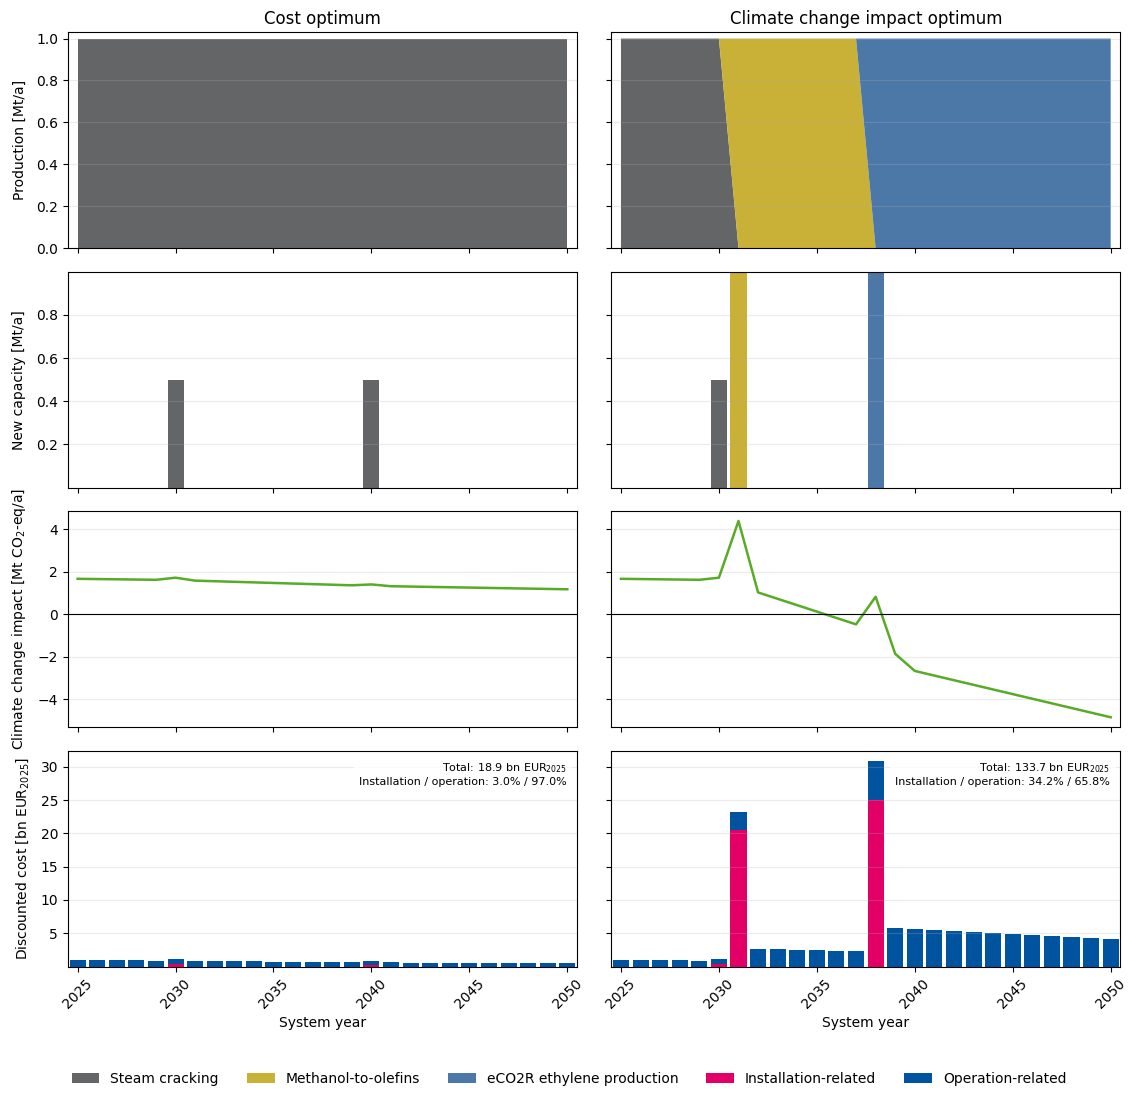

In [24]:
# Extreme pathways: economic and environmental extreme pathways
extreme_models = {
    "Cost optimum": cost_model,
    "Climate change impact optimum": climate_frontier_model,
}
fig, axes = plt.subplots(4, 2, figsize=(11.5, 11.0), sharex="col", sharey="row")
cost_colors = {
    "installation_related": "#E30066",
    "operation_related": "#00549F",
}

for column, (title, model) in enumerate(extreme_models.items()):
    production, new_capacity = route_result_tables(model)
    production_mt = production / 1e9
    capacity_mt = new_capacity / 1e9
    climate_mt = annual_climate_impacts(model).sum(axis=1) / 1e9
    costs = annual_costs(model)
    discount_factors = pd.Series(
        {year: pyo.value(model.discount_factor[year]) for year in model.SYSTEM_TIME}
    )
    discounted_costs = costs.mul(discount_factors, axis=0) / 1e9
    cost_breakdown = discounted_cost_breakdown(model)

    axes[0, column].stackplot(
        production_mt.index,
        *[production_mt[route] for route in ROUTE_CODES],
        labels=[PROCESS_NAMES[route] for route in ROUTE_CODES],
        colors=[PLOT_COLORS[route] for route in ROUTE_CODES],
    )
    axes[0, column].set_title(title)
    axes[0, column].set_ylim(0, 1.03)
    axes[0, column].grid(axis="y", alpha=0.25)
    axes[0, column].tick_params(axis="x", labelbottom=False)

    cumulative_capacity = np.zeros(len(capacity_mt.index))
    for route in ROUTE_CODES:
        values = capacity_mt[route].to_numpy()
        axes[1, column].bar(
            capacity_mt.index,
            values,
            bottom=cumulative_capacity,
            width=0.82,
            color=PLOT_COLORS[route],
            label=PROCESS_NAMES[route],
        )
        cumulative_capacity += values
    axes[1, column].grid(axis="y", alpha=0.25)
    axes[1, column].tick_params(axis="x", labelbottom=False)

    axes[2, column].plot(
        climate_mt.index,
        climate_mt,
        color="#57AB27",
        linewidth=1.8,
    )
    axes[2, column].axhline(0.0, color="black", linewidth=0.8)
    axes[2, column].grid(axis="y", alpha=0.25)
    axes[2, column].tick_params(axis="x", labelbottom=False)

    cumulative_cost = np.zeros(len(discounted_costs.index))
    for cost_type in ("installation_related", "operation_related"):
        values = discounted_costs[cost_type].to_numpy()
        axes[3, column].bar(
            discounted_costs.index,
            values,
            bottom=cumulative_cost,
            width=0.82,
            color=cost_colors[cost_type],
            label=(
                "Installation-related"
                if cost_type == "installation_related"
                else "Operation-related"
            ),
        )
        cumulative_cost += values
    axes[3, column].grid(axis="y", alpha=0.25)
    axes[3, column].set_xlabel("System year")
    axes[3, column].set_xticks(np.arange(2025, 2051, 5))
    axes[3, column].tick_params(axis="x", rotation=45)
    axes[3, column].text(
        0.98,
        0.95,
        (
            f"Total: {pyo.value(model.total_cost) / 1e9:.1f} bn EUR$_{{2025}}$\n"
            f"Installation / operation: "
            f"{100 * cost_breakdown['installation_cost_share']:.1f}% / "
            f"{100 * cost_breakdown['operation_cost_share']:.1f}%"
        ),
        transform=axes[3, column].transAxes,
        ha="right",
        va="top",
        fontsize=8,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8},
    )

for axis in axes.flat:
    axis.set_xlim(2024.5, 2050.5)
axes[0, 0].set_ylabel("Production [Mt/a]", labelpad=7)
axes[1, 0].set_ylabel("New capacity [Mt/a]", labelpad=7)
axes[2, 0].set_ylabel("Climate change impact [Mt CO$_2$-eq/a]", labelpad=7)
axes[3, 0].set_ylabel("Discounted cost [bn EUR$_{2025}$]", labelpad=7)
route_handles, route_labels = axes[0, 0].get_legend_handles_labels()
cost_handles, cost_labels = axes[3, 0].get_legend_handles_labels()
fig.legend(
    route_handles + cost_handles,
    route_labels + cost_labels,
    loc="lower center",
    ncol=5,
    frameon=False,
)
fig.tight_layout(rect=(0, 0.045, 1, 1))
save_thesis_figure(fig, "figure_5_1_extreme_pathways")
plt.show()


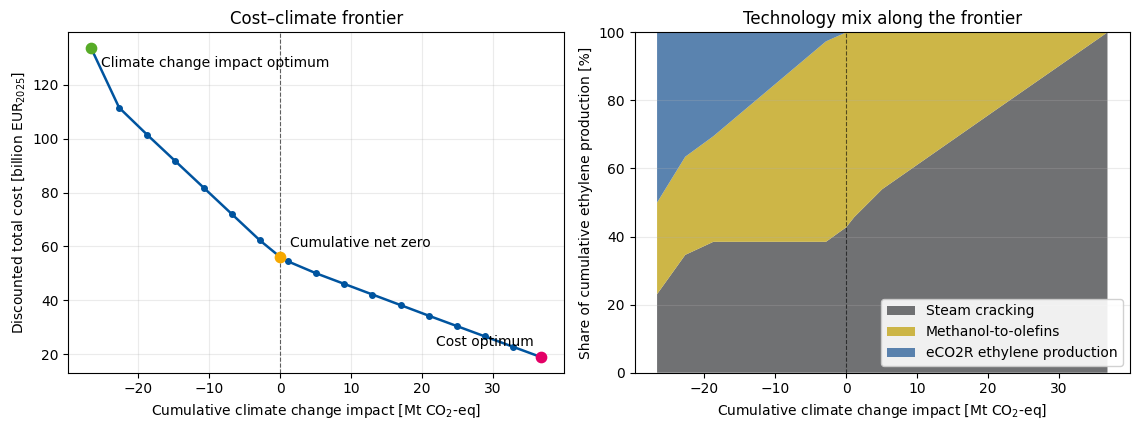

In [25]:
# Cost--climate frontier: cost--impact frontier and associated technology mix
curve = sweep_results.sort_values("cumulative_climate_kg_CO2eq")
x_impact = curve["cumulative_climate_kg_CO2eq"] / 1e9
y_cost = curve["discounted_cost_EUR_2025"] / 1e9

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharex=True)
axes[0].plot(
    x_impact,
    y_cost,
    color="#00549F",
    marker="o",
    markersize=4,
    linewidth=1.8,
)

key_points = {
    "Climate change impact optimum": climate_frontier_row,
    "Cumulative net zero": net_zero_row,
    "Cost optimum": curve.iloc[-1],
}
point_colors = {
    "Climate change impact optimum": "#57AB27",
    "Cumulative net zero": "#F6A800",
    "Cost optimum": "#E30066",
}
annotation_offsets = {
    "Climate change impact optimum": (7, -14),
    "Cumulative net zero": (7, 7),
    "Cost optimum": (-76, 8),
}
for label, row in key_points.items():
    point = (
        row["cumulative_climate_kg_CO2eq"] / 1e9,
        row["discounted_cost_EUR_2025"] / 1e9,
    )
    axes[0].scatter(*point, color=point_colors[label], s=55, zorder=3)
    axes[0].annotate(
        label,
        point,
        xytext=annotation_offsets[label],
        textcoords="offset points",
    )

axes[0].axvline(0.0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
axes[0].set_ylabel("Discounted total cost [billion EUR$_{2025}$]")
axes[0].set_title("Cost–climate frontier")
axes[0].grid(alpha=0.25)

axes[1].stackplot(
    x_impact,
    *[100 * curve[f"share_{route}"] for route in ROUTE_CODES],
    labels=[PROCESS_NAMES[route] for route in ROUTE_CODES],
    colors=[PLOT_COLORS[route] for route in ROUTE_CODES],
    alpha=0.92,
)
axes[1].axvline(0.0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Share of cumulative ethylene production [%]")
axes[1].set_title("Technology mix along the frontier")
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(
    frameon=True,
    facecolor="white",
    framealpha=0.9,
    loc="lower right",
)

for axis in axes:
    axis.set_xlabel("Cumulative climate change impact [Mt CO$_2$-eq]")
fig.tight_layout()
save_thesis_figure(fig, "figure_5_2_cost_impact_frontier")
plt.show()


In [26]:
# Incremental abatement costs between adjacent baseline solutions.
abatement_curve = sweep_results.sort_values(
    "cumulative_climate_kg_CO2eq",
    ascending=False,
).reset_index(drop=True)
abatement_curve["cumulative_abatement_kg_CO2eq"] = (
    COST_MINIMUM_IMPACT - abatement_curve["cumulative_climate_kg_CO2eq"]
)

abatement_intervals = pd.DataFrame({
    "from_cumulative_climate_kg_CO2eq": abatement_curve[
        "cumulative_climate_kg_CO2eq"
    ].iloc[:-1].to_numpy(),
    "to_cumulative_climate_kg_CO2eq": abatement_curve[
        "cumulative_climate_kg_CO2eq"
    ].iloc[1:].to_numpy(),
    "abatement_start_kg_CO2eq": abatement_curve[
        "cumulative_abatement_kg_CO2eq"
    ].iloc[:-1].to_numpy(),
    "abatement_end_kg_CO2eq": abatement_curve[
        "cumulative_abatement_kg_CO2eq"
    ].iloc[1:].to_numpy(),
    "cost_start_EUR_2025": abatement_curve[
        "discounted_cost_EUR_2025"
    ].iloc[:-1].to_numpy(),
    "cost_end_EUR_2025": abatement_curve[
        "discounted_cost_EUR_2025"
    ].iloc[1:].to_numpy(),
})
abatement_intervals["additional_abatement_kg_CO2eq"] = (
    abatement_intervals["abatement_end_kg_CO2eq"]
    - abatement_intervals["abatement_start_kg_CO2eq"]
)
abatement_intervals["additional_cost_EUR_2025"] = (
    abatement_intervals["cost_end_EUR_2025"]
    - abatement_intervals["cost_start_EUR_2025"]
)
if not (abatement_intervals["additional_abatement_kg_CO2eq"] > 0).all():
    raise RuntimeError("The sweep contains a non-positive abatement interval.")
if not (abatement_intervals["additional_cost_EUR_2025"] >= -1.0).all():
    raise RuntimeError("Minimum cost decreases when the climate budget is tightened.")
abatement_intervals["incremental_cost_EUR_2025_per_t_CO2eq"] = (
    abatement_intervals["additional_cost_EUR_2025"]
    / abatement_intervals["additional_abatement_kg_CO2eq"]
    * 1000.0
)
if not np.isfinite(
    abatement_intervals["incremental_cost_EUR_2025_per_t_CO2eq"]
).all():
    raise RuntimeError("Incremental abatement costs contain non-finite values.")

abatement_intervals.to_csv(
    results_dir / "baseline_incremental_abatement_costs.csv",
    index=False,
)
abatement_intervals[
    [
        "from_cumulative_climate_kg_CO2eq",
        "to_cumulative_climate_kg_CO2eq",
        "additional_abatement_kg_CO2eq",
        "additional_cost_EUR_2025",
        "incremental_cost_EUR_2025_per_t_CO2eq",
    ]
]


,from_cumulative_climate_kg_CO2eq,to_cumulative_climate_kg_CO2eq,additional_abatement_kg_CO2eq,additional_cost_EUR_2025,incremental_cost_EUR_2025_per_t_CO2eq
0,3.682012e+10,3.285267e+10,3.967447e+09,3.855263e+09,971.723942
1,3.285267e+10,2.888522e+10,3.967447e+09,3.855263e+09,971.723942
2,2.888522e+10,2.491778e+10,3.967447e+09,3.855263e+09,971.723942
3,2.491778e+10,2.095033e+10,3.967447e+09,3.855263e+09,971.723942
4,2.095033e+10,1.698288e+10,3.967447e+09,3.931987e+09,991.062094
5,1.698288e+10,1.301544e+10,3.967447e+09,3.933261e+09,991.383336
6,1.301544e+10,9.047989e+09,3.967447e+09,3.933261e+09,991.383336
7,9.047989e+09,5.080542e+09,3.967447e+09,3.933261e+09,991.383336
8,5.080542e+09,1.113094e+09,3.967447e+09,4.428484e+09,1116.204981
9,1.113094e+09,-1.062934e-06,1.113094e+09,1.641701e+09,1474.898702


## 11. Sensitivity to market prices and technology maturation

The sensitivity analysis varies two sets of assumptions independently. The market-price
scenarios change electricity, natural-gas and fossil-feedstock prices. The technology-
maturation scenarios change selected operating exchanges and installation prices of the
emerging routes. `Constant prices` combined with `No maturation` is the reference used in
the preceding cost--climate analysis.

The two input tables are stored with the case-study data. Market-price factors are based on
the relative differences between the resource-price scenarios and the SDS path reported by
Zibunas et al. (2022), normalized to one in 2025. Technology maturation follows one normalized
S-curve. Moderate maturation applies half of each reduction specified for advanced maturation.


The constant-price scenario deliberately preserves the assumptions used for the
preceding cost--climate analysis. The two outer market scenarios use relative
price changes derived from Zibunas et al. (2022), Supplementary Method 4 and
Table 4. Technology maturation follows a qualitative maturity hierarchy: no
improvement is assigned to established steam cracking, moderate improvement to
the methanol route, and the strongest improvement to the less mature eCO2R
route. A common normalized S-curve describes the timing; its endpoint differs
by process and scenario. These are structured sensitivity assumptions, not
forecasts.

In [27]:
market_price_assumptions = pd.read_csv(
    repo_root / "notebooks" / "data" / "ethylene_case_study"
    / "market_price_scenarios.csv"
)
maturation_assumptions = pd.read_csv(
    repo_root / "notebooks" / "data" / "ethylene_case_study"
    / "technology_maturation_scenarios.csv"
)

MARKET_PRICE_SCENARIOS = (
    "fossil_favorable",
    "constant_prices",
    "electrification_favorable",
)
MATURATION_INTENSITIES = {
    "no_maturation": 0.0,
    "moderate_maturation": 0.5,
    "advanced_maturation": 1.0,
}
MARKET_PRICE_LABELS = {
    "fossil_favorable": "Fossil-favorable",
    "constant_prices": "Constant prices",
    "electrification_favorable": "Electrification-favorable",
}
MATURATION_LABELS = {
    "no_maturation": "No maturation",
    "moderate_maturation": "Moderate maturation",
    "advanced_maturation": "Advanced maturation",
}

display(
    market_price_assumptions.loc[
        market_price_assumptions["year"].isin([2025, 2030, 2040, 2050]),
        [
            "year", "scenario", "electricity_factor",
            "natural_gas_factor", "fossil_feedstock_factor",
        ],
    ].reset_index(drop=True)
)
display(
    maturation_assumptions[
        [
            "change_type", "process", "input_flow",
            "advanced_reduction_2050", "moderate_share_of_advanced",
        ]
    ]
)


,year,scenario,electricity_factor,natural_gas_factor,fossil_feedstock_factor
0,2025,fossil_favorable,1.000000,1.000000,1.000000
1,2030,fossil_favorable,1.000000,0.964912,0.947368
2,2040,fossil_favorable,1.000000,0.901639,0.843750
3,2050,fossil_favorable,1.000000,0.833333,0.760563
4,2025,constant_prices,1.000000,1.000000,1.000000
5,2030,constant_prices,1.000000,1.000000,1.000000
6,2040,constant_prices,1.000000,1.000000,1.000000
7,2050,constant_prices,1.000000,1.000000,1.000000
8,2025,electrification_favorable,1.000000,1.000000,1.000000
9,2030,electrification_favorable,0.473453,1.072125,1.162679


,change_type,process,input_flow,advanced_reduction_2050,moderate_share_of_advanced
0,operating_exchange,mto,interface_electricity_mv,0.10,0.5
1,operating_exchange,mto,interface_cooling,0.10,0.5
2,operating_exchange,mto,interface_cooling_minus_25,0.10,0.5
3,operating_exchange,mto,interface_cooling_minus_100,0.10,0.5
4,operating_exchange,co2_hydrogenation,interface_electricity_mv,0.15,0.5
5,operating_exchange,pem,interface_electricity_mv,0.15,0.5
6,operating_exchange,dac,interface_electricity_mv,0.20,0.5
7,operating_exchange,dac,interface_heat_pump,0.20,0.5
8,operating_exchange,eco2r,interface_electricity_mv,0.30,0.5
9,operating_exchange,eco2r,interface_cooling,0.20,0.5


### 11.1 Scenario-specific model inputs

Each scenario starts from the same validated baseline inputs. Market-price factors are
applied to the time-specific purchase prices. Maturation factors are applied separately to
selected process exchanges and installation prices. The optimization formulation and all
other case-study assumptions remain unchanged.


In [28]:
SENSITIVITY_YEARS = tuple(int(year) for year in scenario_inputs.SYSTEM_TIME)
price_factors = market_price_assumptions.set_index(["scenario", "year"])

ELECTRICITY_DERIVED_PRICE_FLOWS = {
    "interface_electricity_mv",
    "interface_electricity_mv_deu",
    "interface_heat_pump",
    "interface_compressed_air",
    "interface_cooling_minus_15",
    "interface_cooling_minus_25",
    "interface_cooling_minus_45",
    "interface_cooling_minus_55",
    "interface_cooling_minus_100",
}
NATURAL_GAS_PRICE_FLOWS = {"interface_industrial_heat"}
FOSSIL_FEEDSTOCK_PRICE_FLOWS = {"steam_cracking_feedstock_mix"}
MIXED_COOLING_FLOW = "interface_cooling"


def normalized_s_curve(year, start_year=2025, end_year=2050):
    # Smooth transition from zero to one over the study period.
    x = np.clip((year - start_year) / (end_year - start_year), 0.0, 1.0)
    return 3.0 * x**2 - 2.0 * x**3


def build_vintage_improvements(maturation_scenario):
    intensity = MATURATION_INTENSITIES[maturation_scenario]
    if intensity == 0.0:
        return None
    assumptions_op = maturation_assumptions.query(
        "change_type == 'operating_exchange'"
    )
    return {
        (row.process, row.input_flow, year): (
            1.0
            - intensity
            * row.advanced_reduction_2050
            * normalized_s_curve(year)
        )
        for row in assumptions_op.itertuples(index=False)
        for year in SENSITIVITY_YEARS
    }


def price_factor(price_scenario, group, year):
    return float(price_factors.loc[(price_scenario, year), f"{group}_factor"])


def build_operation_prices(price_scenario):
    baseline = scenario_inputs.intermediate_costs_op
    updated = dict(baseline)
    if price_scenario == "constant_prices":
        return updated

    baseline_electricity = baseline[("interface_electricity_mv", 2025)]
    baseline_gas_heat = baseline[("interface_industrial_heat", 2025)]
    for year in SENSITIVITY_YEARS:
        electricity = price_factor(price_scenario, "electricity", year)
        natural_gas = price_factor(price_scenario, "natural_gas", year)
        feedstock = price_factor(price_scenario, "fossil_feedstock", year)
        for flow in ELECTRICITY_DERIVED_PRICE_FLOWS:
            updated[(flow, year)] = baseline[(flow, 2025)] * electricity
        for flow in NATURAL_GAS_PRICE_FLOWS:
            updated[(flow, year)] = baseline[(flow, 2025)] * natural_gas
        for flow in FOSSIL_FEEDSTOCK_PRICE_FLOWS:
            updated[(flow, year)] = baseline[(flow, 2025)] * feedstock

        # The mixed cooling proxy contains natural-gas heat and electricity.
        updated[(MIXED_COOLING_FLOW, year)] = (
            1.67 * baseline_gas_heat * natural_gas
            + 0.0200 * baseline_electricity * electricity
        )
    return updated


def build_installation_prices(maturation_scenario):
    intensity = MATURATION_INTENSITIES[maturation_scenario]
    baseline = scenario_inputs.intermediate_costs_cap
    updated = dict(baseline)
    if intensity == 0.0:
        return updated
    assumptions_cap = maturation_assumptions.query(
        "change_type == 'installation_price'"
    )
    for row in assumptions_cap.itertuples(index=False):
        for year in SENSITIVITY_YEARS:
            updated[(row.input_flow, year)] = baseline[(row.input_flow, 2025)] * (
                1.0
                - intensity
                * row.advanced_reduction_2050
                * normalized_s_curve(year)
            )
    return updated


def build_sensitivity_inputs(price_scenario, maturation_scenario):
    data = scenario_inputs.model_dump()
    data["intermediate_costs_op"] = build_operation_prices(price_scenario)
    data["intermediate_costs_cap"] = build_installation_prices(
        maturation_scenario
    )
    data["vintage_improvements"] = build_vintage_improvements(
        maturation_scenario
    )
    return converter.OptimizationModelInputs(**data)


In [29]:
# Validate the scenario definitions before starting the optimization sweep.
assert set(market_price_assumptions["scenario"]) == set(MARKET_PRICE_SCENARIOS)
assert set(market_price_assumptions["year"]) == set(SENSITIVITY_YEARS)
assert np.allclose(
    market_price_assumptions.query("year == 2025")[[
        "electricity_factor", "natural_gas_factor", "fossil_feedstock_factor"
    ]],
    1.0,
)

reference_inputs = build_sensitivity_inputs(
    "constant_prices", "no_maturation"
)
assert reference_inputs.vintage_improvements is None
assert reference_inputs.intermediate_costs_op == scenario_inputs.intermediate_costs_op
assert reference_inputs.intermediate_costs_cap == scenario_inputs.intermediate_costs_cap

known_processes = set(scenario_inputs.PROCESS)
known_flows = set(scenario_inputs.INTERMEDIATE_FLOW)
operating_rows = maturation_assumptions.query(
    "change_type == 'operating_exchange'"
)
installation_rows = maturation_assumptions.query(
    "change_type == 'installation_price'"
)
assert set(operating_rows["process"]).issubset(known_processes)
assert set(operating_rows["input_flow"]).issubset(known_flows)
assert set(installation_rows["input_flow"]).issubset(known_flows)

for price_scenario in MARKET_PRICE_SCENARIOS:
    prices = build_operation_prices(price_scenario)
    assert set(prices) == set(scenario_inputs.intermediate_costs_op)
    assert all(np.isfinite(value) for value in prices.values())

print("Sensitivity inputs validated.")


Sensitivity inputs validated.

### 11.2 Cost--climate frontiers

For each maturation scenario, environmental optimization first determines the lowest
feasible cumulative climate change impact. Each of the nine scenario combinations is then solved
at 17 evenly spaced limits between its cost and climate change impact optima. An
additional budget of zero provides the common cumulative net-zero comparison. Results are
saved after every completed frontier so that an interrupted run can be resumed from the
exported records.


In [30]:
import gc

FRONTIER_REGULAR_POINTS = 17
CLIMATE_ENDPOINT_RELATIVE_TOLERANCE = 1e-8


def solve_sensitivity_model(inputs, name, objective):
    model = optimizer.create_model(
        inputs,
        name=name,
        objective_category="climate_change",
        objective=objective,
    )
    try:
        solved, objective_value, results = optimizer.solve_model(
            model,
            solver_name=SOLVER,
            tee=False,
            load_solutions=False,
        )
    except RuntimeError as error:
        if "termination: unknown" not in str(error):
            raise
        solved, objective_value, results = optimizer.solve_model(
            model,
            solver_name=SOLVER,
            tee=False,
            load_solutions=False,
            solver_options={"user_bound_scale": -14},
        )
    termination = str(results.solver.termination_condition)
    if termination.lower() != "optimal":
        raise RuntimeError(f"{name} terminated with {termination}.")
    return solved, float(objective_value), termination


def inputs_with_climate_budget(inputs, climate_budget):
    data = inputs.model_dump()
    data["cumulative_category_impact_limits"] = {
        "climate_change": float(climate_budget)
    }
    return converter.OptimizationModelInputs(**data)


def route_summary(model):
    production, _ = route_result_tables(model)
    route_output = production.sum(axis=0)
    total_output = float(route_output.sum())
    summary = {
        f"share_{route}": float(route_output[route] / total_output)
        for route in ROUTE_CODES
    }
    for route in ROUTE_CODES:
        active_years = production.index[production[route] > 1e-6]
        summary[f"first_year_{route}"] = (
            int(active_years.min()) if len(active_years) else np.nan
        )
    return summary


climate_endpoints = {}
for maturation_scenario in MATURATION_INTENSITIES:
    endpoint_inputs = build_sensitivity_inputs(
        "constant_prices", maturation_scenario
    )
    endpoint_model, endpoint_objective, _ = solve_sensitivity_model(
        endpoint_inputs,
        f"climate_endpoint_{maturation_scenario}",
        "environmental",
    )
    endpoint_impact = cumulative_climate_impact(endpoint_model)
    if not np.isclose(endpoint_impact, endpoint_objective, rtol=1e-8, atol=1.0):
        raise RuntimeError("Environmental objective and cumulative impact disagree.")
    tolerance = max(
        1.0,
        CLIMATE_ENDPOINT_RELATIVE_TOLERANCE * abs(endpoint_impact),
    )
    climate_endpoints[maturation_scenario] = {
        "impact": endpoint_impact,
        "budget": endpoint_impact + tolerance,
    }
    del endpoint_model


frontier_records = []
for maturation_scenario in MATURATION_INTENSITIES:
    endpoint = climate_endpoints[maturation_scenario]
    for price_scenario in MARKET_PRICE_SCENARIOS:
        base_inputs = build_sensitivity_inputs(
            price_scenario, maturation_scenario
        )
        cost_model_sensitivity, cost_objective_sensitivity, termination = (
            solve_sensitivity_model(
                base_inputs,
                f"cost_minimum_{price_scenario}_{maturation_scenario}",
                "cost",
            )
        )
        cost_minimum_impact = cumulative_climate_impact(cost_model_sensitivity)
        if not endpoint["budget"] <= NET_ZERO_BUDGET <= cost_minimum_impact:
            raise RuntimeError("Net zero lies outside the feasible climate range.")

        regular_budgets = np.linspace(
            cost_minimum_impact,
            endpoint["budget"],
            FRONTIER_REGULAR_POINTS,
        )
        budgets = np.unique(np.append(regular_budgets, NET_ZERO_BUDGET))[::-1]

        for point_number, climate_budget in enumerate(budgets):
            if np.isclose(
                climate_budget, cost_minimum_impact, rtol=1e-12, atol=1.0
            ):
                solved_model = cost_model_sensitivity
                objective_value = cost_objective_sensitivity
                point_type = "cost_minimum"
            else:
                constrained_inputs = inputs_with_climate_budget(
                    base_inputs, climate_budget
                )
                solved_model, objective_value, termination = solve_sensitivity_model(
                    constrained_inputs,
                    f"frontier_{price_scenario}_{maturation_scenario}_{point_number:02d}",
                    "cost",
                )
                if np.isclose(climate_budget, NET_ZERO_BUDGET, atol=1.0):
                    point_type = "net_zero"
                elif np.isclose(climate_budget, endpoint["budget"], atol=1.0):
                    point_type = "climate_minimum"
                else:
                    point_type = "intermediate"

            realized_impact = cumulative_climate_impact(solved_model)
            feasibility_tolerance = max(1.0, 1e-8 * abs(climate_budget))
            if realized_impact > climate_budget + feasibility_tolerance:
                raise RuntimeError("A solution exceeds its cumulative climate budget.")

            cost_breakdown = discounted_cost_breakdown(solved_model)
            frontier_records.append({
                "maturation_scenario": maturation_scenario,
                "price_scenario": price_scenario,
                "point_number": point_number,
                "point_type": point_type,
                "solver_termination": termination,
                "climate_ambition": float(
                    (cost_minimum_impact - climate_budget)
                    / (cost_minimum_impact - endpoint["impact"])
                ),
                "climate_budget_kg_CO2eq": float(climate_budget),
                "cumulative_climate_kg_CO2eq": float(realized_impact),
                "discounted_cost_EUR_2025": float(objective_value),
                **cost_breakdown,
                **route_summary(solved_model),
            })
            if solved_model is not cost_model_sensitivity:
                del solved_model
            gc.collect()

        pd.DataFrame(frontier_records).to_csv(
            results_dir / "chapter_5_3_frontier_sensitivity.csv",
            index=False,
        )
        print(
            f"Completed {MARKET_PRICE_LABELS[price_scenario]} / "
            f"{MATURATION_LABELS[maturation_scenario]} ({len(budgets)} points)."
        )
        del cost_model_sensitivity
        gc.collect()

sensitivity_frontiers = pd.DataFrame(frontier_records)
for share_column in [f"share_{route}" for route in ROUTE_CODES]:
    sensitivity_frontiers.loc[
        sensitivity_frontiers[share_column].abs() < 1e-10,
        share_column,
    ] = 0.0

for _, group in sensitivity_frontiers.groupby(
    ["maturation_scenario", "price_scenario"]
):
    ordered = group.sort_values("climate_budget_kg_CO2eq", ascending=False)
    if (ordered["discounted_cost_EUR_2025"].diff().dropna() < -100.0).any():
        raise RuntimeError("A tighter climate budget reduces minimum cost.")

sensitivity_frontiers.to_csv(
    results_dir / "chapter_5_3_frontier_sensitivity.csv",
    index=False,
)


2026-09-23 17:46:41.831 | INFO     | optimex.optimizer:create_model:148 - Creating sets


2026-09-23 17:46:41.835 | INFO     | optimex.optimizer:create_model:188 - Creating parameters


2026-09-23 17:46:42.558 | INFO     | optimex.optimizer:create_model:613 - Creating variables


2026-09-23 17:46:44.608 | INFO     | optimex.optimizer:solve_model:1362 - Solver [highs] termination: optimal


2026-09-23 17:46:44.687 | INFO     | optimex.optimizer:solve_model:1378 - Objective (scaled): -350092


2026-09-23 17:46:44.691 | INFO     | optimex.optimizer:solve_model:1379 - Objective (real):   -2.6659e+10


... (827 outputs left out)

2026-09-23 18:10:30.467 | INFO     | optimex.optimizer:create_model:613 - Creating variables


2026-09-23 18:10:33.147 | INFO     | optimex.optimizer:solve_model:1362 - Solver [highs] termination: optimal


2026-09-23 18:10:33.254 | INFO     | optimex.optimizer:solve_model:1368 - Objective (cost): 9.11681e+10


Completed Electrification-favorable / Advanced maturation (18 points).

### 11.3 Scenario results

The tables below extract the cost optimum without a climate change impact constraint, cumulative net-zero solution and climate change impact optimum
from each frontier. They provide the numerical results used in Section 4.2.3 and the exported result tables.


In [31]:
reference_points = sensitivity_frontiers.loc[
    sensitivity_frontiers["point_type"].isin(
        ["cost_minimum", "net_zero", "climate_minimum"]
    )
].copy()
net_zero_scenarios = reference_points.loc[
    reference_points["point_type"] == "net_zero"
].copy()

reference_points.to_csv(
    results_dir / "chapter_5_3_reference_points.csv",
    index=False,
)
net_zero_scenarios.to_csv(
    results_dir / "chapter_5_3_netzero_summary.csv",
    index=False,
)

baseline_checks = {
    "cost_minimum": (float(cost_objective), COST_MINIMUM_IMPACT),
    "net_zero": (
        float(net_zero_row["discounted_cost_EUR_2025"]),
        float(net_zero_row["cumulative_climate_kg_CO2eq"]),
    ),
    "climate_minimum": (
        float(climate_frontier_row["discounted_cost_EUR_2025"]),
        float(climate_frontier_row["cumulative_climate_kg_CO2eq"]),
    ),
}
sensitivity_reference = reference_points.query(
    "maturation_scenario == 'no_maturation' and "
    "price_scenario == 'constant_prices'"
).set_index("point_type")
for point_type, (expected_cost, expected_impact) in baseline_checks.items():
    observed = sensitivity_reference.loc[point_type]
    assert np.isclose(observed["discounted_cost_EUR_2025"], expected_cost, rtol=1e-8)
    assert np.isclose(observed["cumulative_climate_kg_CO2eq"], expected_impact, rtol=1e-8, atol=1.0)

cost_minimum_table = reference_points.query("point_type == 'cost_minimum'").pivot(
    index="maturation_scenario",
    columns="price_scenario",
    values="discounted_cost_EUR_2025",
).loc[list(MATURATION_INTENSITIES), list(MARKET_PRICE_SCENARIOS)] / 1e9
net_zero_table = net_zero_scenarios[
    [
        "maturation_scenario", "price_scenario",
        "discounted_cost_EUR_2025", "share_steam_cracking",
        "share_mto", "share_eco2r", "first_year_mto",
    ]
].copy()
net_zero_table["discounted_cost_EUR_2025"] /= 1e9
for route in ROUTE_CODES:
    net_zero_table[f"share_{route}"] *= 100
climate_minimum_table = reference_points.query("point_type == 'climate_minimum'")[
    [
        "maturation_scenario", "price_scenario",
        "cumulative_climate_kg_CO2eq", "discounted_cost_EUR_2025",
    ]
].copy()
climate_minimum_table["cumulative_climate_kg_CO2eq"] /= 1e9
climate_minimum_table["discounted_cost_EUR_2025"] /= 1e9

display(cost_minimum_table.round(2))
display(net_zero_table.round(2))
display(climate_minimum_table.round(2))


price_scenario,fossil_favorable,constant_prices,electrification_favorable
maturation_scenario,,,
no_maturation,16.85,18.85,24.4
moderate_maturation,16.85,18.85,24.4
advanced_maturation,16.85,18.85,24.4


,maturation_scenario,price_scenario,discounted_cost_EUR_2025,share_steam_cracking,share_mto,share_eco2r,first_year_mto
10,no_maturation,fossil_favorable,55.60,42.74,57.26,0.00,2036.0
28,no_maturation,constant_prices,56.08,42.74,57.26,0.00,2036.0
46,no_maturation,electrification_favorable,43.98,42.56,57.44,0.00,2036.0
63,moderate_maturation,fossil_favorable,53.28,43.63,56.37,0.00,2036.0
81,moderate_maturation,constant_prices,53.77,43.63,56.37,0.00,2036.0
99,moderate_maturation,electrification_favorable,42.44,43.63,56.37,0.00,2036.0
117,advanced_maturation,fossil_favorable,50.84,46.04,53.07,0.89,2036.0
135,advanced_maturation,constant_prices,51.39,46.03,53.11,0.86,2036.0
153,advanced_maturation,electrification_favorable,40.83,44.50,55.50,0.00,2036.0


,maturation_scenario,price_scenario,cumulative_climate_kg_CO2eq,discounted_cost_EUR_2025
17,no_maturation,fossil_favorable,-26.66,133.19
35,no_maturation,constant_prices,-26.66,133.73
53,no_maturation,electrification_favorable,-26.66,97.60
71,moderate_maturation,fossil_favorable,-28.71,126.51
89,moderate_maturation,constant_prices,-28.71,127.03
107,moderate_maturation,electrification_favorable,-28.71,93.11
125,advanced_maturation,fossil_favorable,-31.20,122.73
143,advanced_maturation,constant_prices,-31.20,123.23
161,advanced_maturation,electrification_favorable,-31.20,91.17


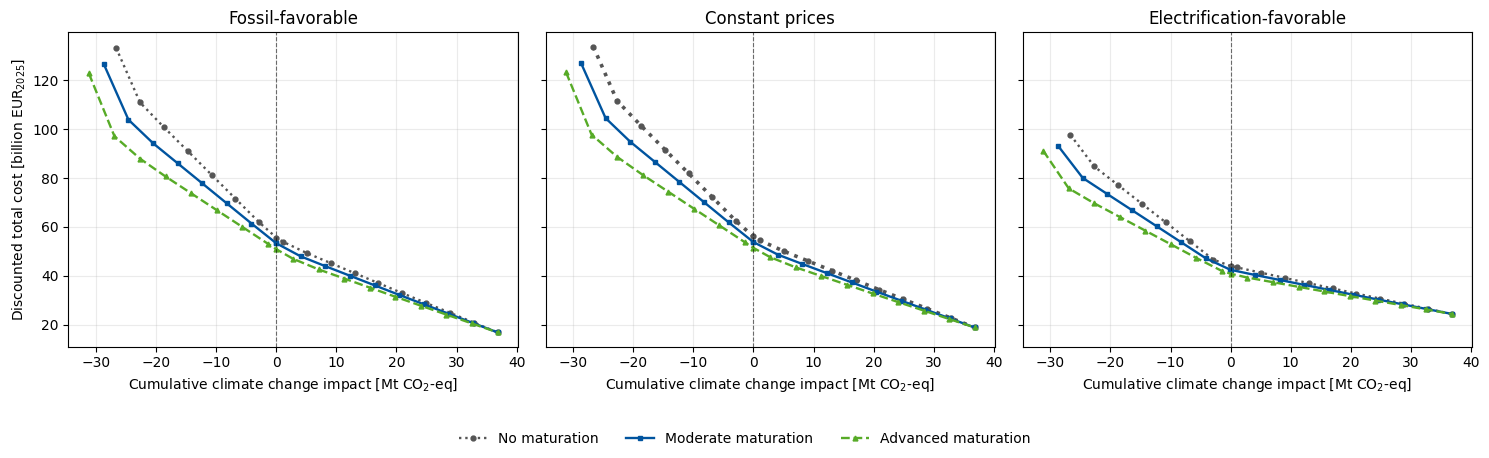

In [32]:
# Sensitivity of the cost--climate frontiers: sensitivity of the cost--climate frontiers.
MATURATION_STYLES = {
    "no_maturation": {"color": "#555555", "linestyle": ":", "marker": "o"},
    "moderate_maturation": {"color": "#00549F", "linestyle": "-", "marker": "s"},
    "advanced_maturation": {"color": "#57AB27", "linestyle": "--", "marker": "^"},
}
fig, axes = plt.subplots(
    1, len(MARKET_PRICE_SCENARIOS), figsize=(15, 4.6), sharey=True
)
for axis, price_scenario in zip(axes, MARKET_PRICE_SCENARIOS):
    for maturation_scenario in MATURATION_INTENSITIES:
        curve = sensitivity_frontiers.loc[
            (sensitivity_frontiers["price_scenario"] == price_scenario)
            & (sensitivity_frontiers["maturation_scenario"] == maturation_scenario)
        ].sort_values("cumulative_climate_kg_CO2eq")
        style = MATURATION_STYLES[maturation_scenario]
        is_reference = (
            price_scenario == "constant_prices"
            and maturation_scenario == "no_maturation"
        )
        axis.plot(
            curve["cumulative_climate_kg_CO2eq"] / 1e9,
            curve["discounted_cost_EUR_2025"] / 1e9,
            label=MATURATION_LABELS[maturation_scenario],
            color=style["color"],
            linestyle=style["linestyle"],
            marker=style["marker"],
            markersize=3.5,
            linewidth=2.6 if is_reference else 1.7,
        )
    axis.axvline(0.0, color="black", linewidth=0.8, linestyle="--", alpha=0.55)
    axis.set_title(MARKET_PRICE_LABELS[price_scenario])
    axis.set_xlabel("Cumulative climate change impact [Mt CO$_2$-eq]")
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Discounted total cost [billion EUR$_{2025}$]")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.10, 1, 1))
save_thesis_figure(fig, "figure_5_3_frontier_sensitivity")
plt.show()


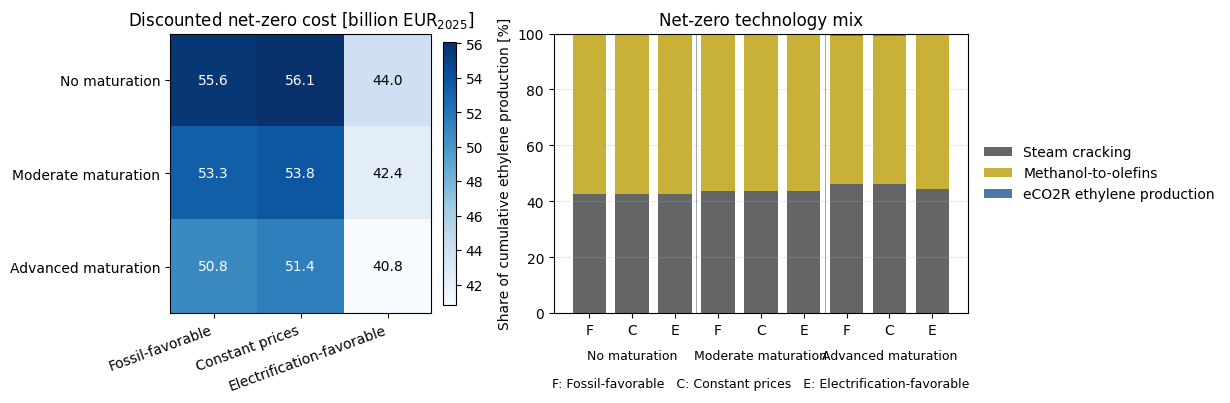

In [33]:
# Net-zero comparison: costs and cumulative production mix at net zero.
net_zero_plot = net_zero_scenarios.copy()
net_zero_plot["maturation_scenario"] = pd.Categorical(
    net_zero_plot["maturation_scenario"],
    categories=list(MATURATION_INTENSITIES),
    ordered=True,
)
net_zero_plot["price_scenario"] = pd.Categorical(
    net_zero_plot["price_scenario"],
    categories=list(MARKET_PRICE_SCENARIOS),
    ordered=True,
)
net_zero_plot = net_zero_plot.sort_values(
    ["maturation_scenario", "price_scenario"]
)

cost_matrix = net_zero_plot.pivot(
    index="maturation_scenario",
    columns="price_scenario",
    values="discounted_cost_EUR_2025",
).loc[list(MATURATION_INTENSITIES), list(MARKET_PRICE_SCENARIOS)] / 1e9

fig, axes = plt.subplots(
    1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.0, 1.45]}
)
image = axes[0].imshow(cost_matrix.to_numpy(), cmap="Blues", aspect="auto")
for row in range(cost_matrix.shape[0]):
    for column in range(cost_matrix.shape[1]):
        value = cost_matrix.iloc[row, column]
        axes[0].text(
            column,
            row,
            f"{value:.1f}",
            ha="center",
            va="center",
            color="white" if value > cost_matrix.to_numpy().mean() else "black",
        )
axes[0].set_xticks(
    range(len(MARKET_PRICE_SCENARIOS)),
    [MARKET_PRICE_LABELS[key] for key in MARKET_PRICE_SCENARIOS],
    rotation=20,
    ha="right",
)
axes[0].set_yticks(
    range(len(MATURATION_INTENSITIES)),
    [MATURATION_LABELS[key] for key in MATURATION_INTENSITIES],
)
axes[0].set_title("Discounted net-zero cost [billion EUR$_{2025}$]")
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)

x = np.arange(len(net_zero_plot))
bottom = np.zeros(len(net_zero_plot))
for route in ROUTE_CODES:
    values = 100.0 * net_zero_plot[f"share_{route}"].to_numpy()
    axes[1].bar(
        x,
        values,
        bottom=bottom,
        color=PLOT_COLORS[route],
        label=PROCESS_NAMES[route],
        width=0.78,
    )
    bottom += values
axes[1].set_xticks(x, ["F", "C", "E"] * len(MATURATION_INTENSITIES))
axes[1].set_ylabel("Share of cumulative ethylene production [%]")
axes[1].set_ylim(0, 100)
axes[1].set_title("Net-zero technology mix")
axes[1].grid(axis="y", alpha=0.25)
for boundary in (2.5, 5.5):
    axes[1].axvline(boundary, color="black", linewidth=0.7, alpha=0.35)
for center, maturation_scenario in zip((1, 4, 7), MATURATION_INTENSITIES):
    axes[1].text(
        center,
        -13,
        MATURATION_LABELS[maturation_scenario].replace(" maturation", ""),
        ha="center",
        va="top",
        fontsize=9,
        clip_on=False,
    )
axes[1].text(
    0.5,
    -0.23,
    "F: Fossil-favorable   C: Constant prices   E: Electrification-favorable",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=9,
)
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout(rect=(0, 0.10, 0.92, 1))
save_thesis_figure(fig, "figure_5_4_netzero_sensitivity")
plt.show()


## 12. Interpretation and model boundary

The case study is designed to demonstrate the economic extension of optimex.
The constant-price analysis isolates the effect of increasingly stringent
constraints on cumulative climate change impact; the sensitivity analysis then varies market-price and
technology-maturation assumptions independently.

The eCO2R route excludes separated co-products. Neither the additional burdens
of purifying these products nor potential product credits are included. The
price and maturation scenarios are illustrative rather than forecasts, and the
results should therefore be interpreted as a demonstration of the analyses
enabled by the framework rather than as predictions for ethylene production.

## References and data sources

- Bareiß, K. et al. (2019). *Life Cycle Assessment of Hydrogen from Proton Exchange Membrane Water Electrolysis in Future Energy Systems*. Applied Energy 237, 862--872. https://doi.org/10.1016/j.apenergy.2019.01.001
- Deutz, S. and Bardow, A. (2021). *Life-cycle assessment of an industrial direct air capture process based on temperature--vacuum swing adsorption*. Nature Energy 6, 203--213. https://doi.org/10.1038/s41560-020-00771-9
- Dimian, A. C. and Bildea, C. S. (2018). *Energy Efficient Methanol-to-Olefins Process*. Chemical Engineering Research and Design 131, 41--54. https://doi.org/10.1016/j.cherd.2017.11.009
- IRENA (2020). *Green Hydrogen Cost Reduction: Scaling up Electrolysers to Meet the 1.5 Degree Celsius Climate Goal*. https://www.irena.org/publications/2020/Dec/Green-hydrogen-cost-reduction
- Leonzio, G. et al. (2022). *Environmental Performance of Different Sorbents Used for Direct Air Capture*. Sustainable Production and Consumption 32, 101--111. https://doi.org/10.1016/j.spc.2022.04.004
- Löffelholz, M. et al. (2023). *Optimized Scalable CuB Catalyst with Promising Carbon Footprint for the Electrochemical CO2 Reduction to Ethylene*. Sustainable Chemistry for Climate Action 3, 100035. https://doi.org/10.1016/j.scca.2023.100035
- Luderer, G. et al. (2025). *REMIND v3.5.1*. Zenodo. https://doi.org/10.5281/zenodo.15857148
- Rihko-Struckmann, L. K. et al. (2010). *Assessment of Methanol Synthesis Utilizing Exhaust CO2 for Chemical Storage of Electrical Energy*. Industrial & Engineering Chemistry Research 49, 11073--11078. https://doi.org/10.1021/ie100508w
- Sacchi, R. et al. (2022). *PRospective EnvironMental Impact asSEment (premise)*. Renewable and Sustainable Energy Reviews 160, 112311. https://doi.org/10.1016/j.rser.2022.112311
- Sievert, K. et al. (2024). *Considering technology characteristics to project future costs of direct air capture*. Joule 8, 979--999. https://doi.org/10.1016/j.joule.2024.02.005
- Tiggeloven, J. L. (2026). *Breaking and re-forming the chemical industry: Optimizing the transition from fossil-based clusters to net zero*. https://doi.org/10.33540/3376
- PlasticsEurope (2018). *PlasticsEurope Recommendation on Steam Cracker Allocation*.
- Bundesnetzagentur (2026). *Der Strommarkt im Jahr 2025: Höchste PV-Einspeisung in jedem Quartal*. https://www.smard.de/page/home/topic-article/444/218954/hoechste-pv-einspeisung-in-jedem-quartal
- Forschungsstelle für Energiewirtschaft (2026). *Deutsche Strompreise an der Börse EPEX Spot im Jahr 2025*. https://www.ffe.de/veroeffentlichungen/deutsche-strompreise-an-der-boerse-epex-spot-im-jahr-2025/
- INSEE (2022). *International Prices of Imported Raw Materials: Naphtha (European Northwest)*. https://www.insee.fr/fr/statistiques/serie/001641575
- Eurostat. *Harmonised Index of Consumer Prices: Annual Data*, dataset `prc_hicp_ainr`. https://doi.org/10.2908/PRC_HICP_AINR
- European Central Bank. *Annual Average USD/EUR Reference Exchange Rate*, series `EXR.A.USD.EUR.SP00.A`. https://data.ecb.europa.eu/data/datasets/EXR/EXR.A.USD.EUR.SP00.A
- Wernet, G. et al. (2016). *The ecoinvent database version 3 (part I): overview and methodology*. The International Journal of Life Cycle Assessment 21, 1218--1230. https://doi.org/10.1007/s11367-016-1087-8
- Wyndorps, J. et al. (2021). *Is Electrochemical CO2 Reduction the Future Technology for Power-to-Chemicals?* Sustainable Energy & Fuels 5, 5748--5761. https://doi.org/10.1039/D1SE00975C
- Zibunas, C. et al. (2022). *Cost-optimal pathways towards net-zero chemicals and plastics based on a circular carbon economy*. Computers & Chemical Engineering 162, 107798. https://doi.org/10.1016/j.compchemeng.2022.107798

Additional price sources, currency conversions, inflation adjustments, and
derived installation-cost calculations are documented row by row in
`cost_inputs.csv` and in `tiggeloven_capex_calculations.md`. The accompanying
scenario CSV files contain the complete market-price and technology-maturation
assumptions used in the sensitivity analysis.